# 旅行规划助手 · 架构与代码导读

> 这是一份「编排者 - 工作者（Orchestrator-Worker）」模式的完整落地：
> **父图**把需求拆成几个城市段，**子图**把每个城市变成一份可执行的攻略。

---

## 1. 最终产出长什么样

```
# 北京 → 山西 行程总览
> 2026-11-20 ~ 2026-11-28 · 2 人 · 总预算 5000元

## 太原（2026-11-20 ~ 2026-11-22 · 3 天）
- 到达：高铁 Gxxx · 北京站 → 太原站 · 08:00–12:30
- Day 1 · 2026-11-20 · 周五 · 晴
  - 13:30–16:30 山西博物院 — 镇馆之宝：鸟尊；需提前预约
- 酒店 / 预算 / 攻略 / 下一站
```

---

## 2. 两层图

```
父图（PlanningState）
┌──────────────┐   Send × N   ┌───────────────┐   region_plans   ┌────────────┐
│ orchestrator │ ───────────► │ region_worker │ ───────────────► │ synthesizer│
│  拆城市段     │   并行 N 个   │  （子图）      │   归约合并        │  渲染攻略   │
└──────────────┘              └───────────────┘                  └────────────┘

子图（WorkerState，只处理一个城市）
prepare ─┬─ scout_leg ────┐
         ├─ scout_poi ────┤
         ├─ scout_hotel ──┼─► merge ─► plan ─► validate ─┬─► finalize ─► END
         ├─ scout_weather ┤                              └─► plan（回炉 1 次）
         └─ scout_guide ──┘
```

---

## 3. 数据怎么流动

| 阶段 | 数据结构 | 谁写 | 谁读 |
|---|---|---|---|
| 拆城市 | `RegionDraft` | `orchestrator`（LLM） | `fan_out_regions` |
| 查事实 | `TransportLeg / POICandidate / HotelCandidate / WeatherDay / GuideNote` | 5 个 scout | `merge` |
| 生成候选集 | `index: dict[id, str]` | `merge`（代码） | `plan`（LLM） |
| 排行程 | `PlannerDraft`（只含 id 引用） | `plan`（LLM） | `validate` / `finalize` |
| 成稿 | `LocalPlan` | `finalize`（代码） | `synthesizer` |
| 总攻略 | `current_plan: str` | `synthesizer`（代码） | 用户 |

---

## 4. 三条贯穿全篇的设计原则

**① LLM 不搬运事实，只做选择。**
事实（景点叫什么、几点开门、门票多少、几点的车）由工具产出、由代码搬运；LLM 只负责"在这堆候选里挑哪些、怎么排"。
这就是 `PlannerDraft` 里只有 `ref: "poi_03"` 而没有景点名的原因。

**② 确定性的事交给代码，创造性的事交给 LLM。**
日期补齐、时间轴、算钱、校验、排序、去重 → 代码；选点、取舍、写理由 → LLM。
上一版 `region_worker` 的问题正是反过来了：把取数交给 ReAct 即兴发挥，把规划交给一段禁止它规划的 prompt。

**③ 每一层都能降级，永不因为一个数据源挂掉而整体失败。**
scout 失败 → 空列表 + `errors`；LLM 失败 → 代码兜底行程；校验失败 → 重试一次后带 `warnings` 出稿。
最终 `LocalPlan.status` 是 `ok / partial / failed`，而不是"假装成功"。

---

## 目录

| 部分 | 内容 |
|---|---|
| 第 1 部分 | 编排层：把需求拆成城市段 |
| 第 2 部分 | 三层数据模型：把「事实」和「判断」分开 |
| 第 3 部分 | State 与 Reducer |
| 第 4 部分 | orchestrator：结构化输出 |
| 第 5 部分 | region_worker 为什么是子图 |
| 第 6 部分 | 取数层：5 个 scout |
| 第 7 部分 | merge → plan → validate → finalize |
| 第 8 部分 | 图接线：并行与扇入 |
| 第 9 部分 | 桥接层：父图节点 vs 子图 |
| 第 10 部分 | synthesizer：渲染 |
| 第 11 部分 | 父图拓扑 |
| 第 12 部分 | 怎么跑、怎么调 |
| 附录 | 术语表 / 排错清单 / 接高德清单 |

---

## 5. 怎么读这份 notebook

按 cell 顺序读，每个代码块前面都有一节说明，回答三个问题：

- **这一段在解决什么问题？**
- **为什么这么写（而不是别的写法）？**
- **涉及的 LangGraph / LangChain 概念是什么？**

In [1]:
import sys

if sys.platform == "win32":
    if "ipykernel" in sys.modules:
        sys.stderr = sys.__stderr__

## 第 1 部分 · 编排层：把需求拆成城市段

### 为什么先拆

用户说"北京出发，去山西玩 7 天，5000 块"。如果直接让 LLM 一次写完 7 天 3 城的攻略，会同时遇到：

- 上下文太长，后面写飞了（第 5 天忘了第 2 天去过哪）
- 城市之间的交通没人负责（谁查？谁串？）
- 预算没法分摊，也不知道有没有超
- 一个城市写失败，整个行程重来

所以先做一次**结构化拆解**，把"一个大问题"变成"N 个独立的小问题"，每个小问题交给一个 worker 并行处理。这就是 Orchestrator-Worker 模式的核心价值：**分而治之 + 可并行**。

### `RegionDraft` 字段说明

| 字段 | 谁填 | 说明 |
|---|---|---|
| `origin` / `destination` | LLM | 城市名（不带"市"） |
| `start_date` / `end_date` | LLM | ISO 日期，段与段首尾相接 |
| `budget` | LLM | 本段预算字符串 |
| `passengers` / `interests` / `transport_mode` | **代码回填** | 见下面 orchestrator 的注释 |

`days` 是个 `@property`，由起止日期算出来，不占字段——避免 LLM 把天数和日期写矛盾。

### 两个 validator 的作用

```python
@field_validator("destination", "origin")   # "太原市" → "太原"
@field_validator("start_date", "end_date")  # 格式不对直接抛错
```

**为什么要有**：LLM 输出偶尔会带"市"、写 `2026/11/20`。这类错误如果留到后面，会让高德的 POI 查询、日期计算全部错位。**在数据入口就把格式钉死**，是后面所有代码能放心用 `strptime` 的前提。

In [2]:
from pydantic import BaseModel, Field, field_validator
from datetime import datetime
from typing import Annotated, List, Literal
from langchain.chat_models import init_chat_model
import operator

from dotenv import load_dotenv
load_dotenv()

# 创建模型
llm = init_chat_model(
    'deepseek-flash',
    extra_body={'thinking': {'type': 'disabled'}}
)


# ============================================================
# 编排层：把用户需求拆成城市段
# ============================================================
class RegionDraft(BaseModel):
    """单个城市的结构化"""

    origin: str = Field(
        description="从哪个城市出发。第一个城市填用户出发地，后续城市填上一个城市名。"
    )
    destination: str = Field(
        description="到哪个城市。只写城市名，不要带省份前缀，不要写'市'字。"
    )
    start_date: str = Field(
        description="开始日期，ISO 格式 YYYY-MM-DD。第一个城市 = 用户出行开始日期；"
                    "后续城市 = 上一个城市的 end_date + 1 天。"
    )
    end_date: str = Field(
        description="结束日期，ISO 格式 YYYY-MM-DD。= start_date + 停留天数 - 1 天。"
    )
    budget: str = Field(
        description="本段预算，如'1500元'。所有城市的 budget 金额之和必须等于用户总预算。"
                    "如果用户给的是'经济型'这类档位而非金额，每段都填'经济型'。"
    )
    # 以下由代码从外层 State 复制，LLM 不填
    passengers: int = Field(default=1)
    interests: str | None = Field(default=None)
    transport_mode: str = Field(default="公共交通")

    @property
    def days(self) -> int:
        return (datetime.strptime(self.end_date, "%Y-%m-%d")
                - datetime.strptime(self.start_date, "%Y-%m-%d")).days + 1

    @field_validator("destination", "origin")
    @classmethod
    def _normalize_city(cls, v: str) -> str:
        s = v.strip()
        if s.endswith("市") and len(s) > 2:
            s = s[:-1]
        return s

    @field_validator("start_date", "end_date")
    @classmethod
    def _check_iso(cls, v: str) -> str:
        datetime.strptime(v, "%Y-%m-%d")   # 格式不对直接抛错
        return v


class RegionDrafts(BaseModel):
    """拆分城市结果的结构化输出"""
    regions: list[RegionDraft] = Field(
        description="按地理顺序排列的城市段，日期必须首尾相接、不重叠、不断裂。",
        min_length=1,
        max_length=6,
    )


planner = llm.with_structured_output(RegionDrafts)


# ============================================================
# 入口契约：从一句自然语言里抽出来的东西
# 全部可空——缺什么由 clarify 节点追问，不要在这里硬塞默认值
# ============================================================
class TripRequest(BaseModel):
    origin: str | None = None
    destination: str | None = None
    start_date: str | None = Field(default=None, description="YYYY-MM-DD")
    end_date: str | None = Field(default=None, description="YYYY-MM-DD")
    budget: str | None = None
    passengers: int | None = None
    interests: str | None = None
    transport_mode: str | None = None

## 第 2 部分 · 三层数据模型：把"事实"和"判断"分开

这是整个重构里最重要的一个决定。看这张表：

| 层 | 类 | 谁产出 | 内容性质 | 能校验吗 |
|---|---|---|---|---|
| **事实层** | `TransportLeg` `POICandidate` `HotelCandidate` `WeatherDay` `GuideNote` | scout（工具） | 客观、可查证 | ✅ 能（有 `source`） |
| **规划层** | `DraftItem` `DraftDay` `PlannerDraft` | planner（LLM） | 主观、只做引用 | ✅ 能（引用必须存在） |
| **输出层** | `ItineraryItem` `DayPlan` `HotelPick` `BudgetBreakdown` `LocalPlan` | finalize（代码） | 最终契约 | ✅ 能（结构固定） |

### 为什么事实层要带 `source` 和 `confidence`

```python
source: str = "estimate"    # 数据从哪来：amap / 12306 / web / estimate / mock
confidence: Literal["high", "medium", "low"] = "low"
```

因为现实是**有些数据根本查不到**：高德给不了实时票价和余票。传统做法是让模型"猜一个"，于是攻略里出现不存在的 G613 二等座 ¥197。

带来源之后，"不知道"变成了一种**合法状态**：`price=None, confidence="low"`，渲染时自动标"（方案级，待核实）"。**不逼模型编，也不假装知道。**

### 为什么规划层只用 `ref` 不用名字

```python
class DraftItem(BaseModel):
    start: str
    kind: Literal["sight", "meal", "transit", "rest"]
    ref: str = ""      # ← 只允许填候选 id，如 "poi_03"
    label: str = ""    # 非景点（吃饭/休息）才用文字
```

只要模型输出的是 `poi_03`，`validate` 里一句 `it.ref not in index` 就能拦住编造。**编造在结构上不可能，而不是靠 prompt 求它别编。**

### `LocalPlan` v2 比 v1 多了什么

| v1 的问题 | v2 的解法 |
|---|---|
| 只有 `origin`，没有到达/离开的具体交通 | `inbound` / `outbound: TransportLeg` |
| `ItineraryItem(time, spot, note)` 装不下区间、门票、预约 | `start/end/kind/title/ref/cost/transport` |
| `hotel: HotelInfo` 只有名字 | `HotelPick` 加区域、价位、为什么住这 |
| 没有预算 | `BudgetBreakdown` + `budget_limit` |
| `guides: list[str]` 没有来源 | `GuideNote{topic, text, source, confidence}` |
| 失败了也长得像成功 | `status` + `warnings` |

> **一句话**：输出契约决定了攻略的上限。schema 装不下的信息，agent 再聪明也写不出来。

In [3]:
# ============================================================
# 事实层：subagent 查回来的东西，每个字段都带 source / confidence
# 原则：这里只装「查得到的事实」，不装「判断」
#
# 阅读约定：
#   X | None = None  →  这个字段允许为空（查不到就是空，不要用 0 或 "" 假装知道）
#   Literal[...]     →  枚举，只能取列出的值
#   source           →  数据从哪来（amap / 12306 / web / estimate / mock）
#   confidence       →  这个值有多可信（非 high 时渲染会标「待核实」）
# ============================================================

class TransportLeg(BaseModel):
    """一段城际交通，例如「北京 → 太原」"""

    mode: Literal["高铁", "飞机", "自驾", "大巴", "火车", "其他"] = "其他"
    # 交通方式。只能从这 6 个里选（不要写"动车""普快"这类表外值）

    service: str | None = None
    # 班次号 / 航班号，例如 "G613"（高铁车次）、"MU5101"（航班）。
    # 只拿到"方案级"信息（知道大概耗时、但没有具体班次）时留空——空是合法状态，不要编

    from_station: str | None = None
    # 出发站 / 机场名，例如 "北京西"、"北京南"、"首都机场T3"。
    # 自驾时这一项填城市名 "北京"

    to_station: str | None = None
    # 到达站 / 机场名，例如 "太原南"、"武宿机场"。自驾时填 "太原"

    depart: str | None = None
    # 出发时刻，24 小时制字符串 "08:30"。
    # 用字符串而不是 time 类型，是为了能直接拼进 prompt 和 markdown，不用格式化

    arrive: str | None = None
    # 到达时刻 "12:30"。planner 用它决定第 1 天最早能从哪里开始排行程

    duration_min: int | None = None
    # 全程耗时，单位「分钟」（270 = 4 小时 30 分）。用数字才能参与时间计算

    price: float | None = None
    # 人均票价（元）。注意是单人价：总价 = 本值 × 人数，由 finalize 统一计算

    booking: str | None = None
    # 购票 / 出行提示，例如 "12306 提前 15 天"、"旺季需抢票"、"自驾注意限行"

    source: str = "estimate"
    # 数据来源：amap（高德）/ 12306 / web / estimate（估算）/ mock（测试假数据）

    confidence: Literal["high", "medium", "low"] = "low"
    # 置信度。不是 high 时，synthesizer 会在这一行末尾标「（方案级，待核实）」


class POICandidate(BaseModel):
    """一个候选景点（由 scout_poi 产出，进入 merge 的候选池）"""

    id: str
    # 候选编号 "poi_01"。planner 只能通过这个 id 引用景点，
    # 这是「防止模型编造景点」的关键：名字由代码从 id 反查，模型没机会写名字

    name: str
    # 景点名，例如 "云冈石窟"（由代码填入，不经过模型）

    category: str = "景点"
    # 类型：博物馆 / 古建 / 石窟 / 公园 / 街区 / 商圈 ...
    # planner 用它做「雨天优先室内」这类判断

    rating: float | None = None
    # 高德评分（0-5）。None = 无评分；merge 按它排序，取前 N 个候选

    address: str | None = None
    # 详细地址（高德返回的 formatted_address），用于展示和打车

    lng: float | None = None
    # 经度（高德 GCJ-02 坐标系）。和 lat 一起用于算点位距离、做「同片区」聚类

    lat: float | None = None
    # 纬度。注意高德用的是 GCJ-02，不是 WGS84，换算会差几百米

    open_hours: str | None = None
    # 开放时间 "08:30-17:30"，含闭馆日如 "09:00-17:00（周一闭馆）"。
    # validate 用它检查「周一别排博物馆」

    ticket: float | None = None
    # 门票（元 / 人）。0 = 免费，None = 不知道（不是 0！）

    ticket_group: str | None = None
    # 联票 / 通票分组，例如「平遥通票」。同一组只需要买一次

    group_price: float | None = None
    # 该通票的价格（元 / 人）。用于「只去了通票内景点、没选通票本身」时补价

    duration_min: int | None = 90
    # 建议游览时长（分钟）。finalize 用它推算「几点结束」，不用模型自己算

    booking_required: bool | None = None
    # 是否必须提前预约。None 表示不确定（不确定就别在攻略里写死"需预约"）

    tips: str | None = None
    # 一句话建议，会显示在攻略的 item 后面，例如 "需提前在公众号预约"

    source: str = "mock"
    # 数据来源，接高德后改成 "amap"


class HotelCandidate(BaseModel):
    """一个候选住宿（由 scout_hotel 产出）"""

    id: str
    # 候选编号 "hotel_01"，planner 用 hotel_ref 引用它

    name: str
    # 酒店名

    area: str
    # 所在片区，例如 "柳巷商圈"、"古城南门"。
    # 这个字段比酒店名更重要：它决定你每天出门往哪走

    price_night: float | None = None
    # 每晚价格（元 / 间）。None = 查不到（酒店价格高德拿不到，要接 OTA）

    why: str | None = None
    # 为什么推荐住这里（一句话），例如 "吃和逛都在步行圈，去晋祠稍远"

    source: str = "mock"
    # 数据来源


class WeatherDay(BaseModel):
    """某一天的天气"""

    date: str
    # 日期 "2026-11-20"，和 DayPlan.date 对齐

    condition: str = "未知"
    # 天气现象："晴" / "多云" / "小雨" / "阵雨" / "阴"

    high: float | None = None
    # 最高气温（℃）

    low: float | None = None
    # 最低气温（℃）

    source: Literal["forecast", "climate", "unknown"] = "unknown"
    # forecast = 真实预报（一般只有未来 3~4 天）
    # climate  = 历史同期常年值（超出预报窗口时用这个，别硬编）
    # unknown  = 没查到


class GuideNote(BaseModel):
    """一条实用攻略"""

    topic: str
    # 分类："交通" / "预约" / "美食" / "避坑" / "门票"。
    # synthesizer 直接拿它当小标题

    text: str
    # 正文，一句话说完

    source: str = "model"
    # 来源：model（模型常识）/ web（搜索）/ mock

    confidence: Literal["high", "medium", "low"] = "low"
    # 置信度。非 high 会在渲染时标「（待核实）」——避免把模型常识当成官方信息


# ============================================================
# 规划层：LLM 只能「引用候选 id」，不能凭空写名字
# 注意：这一层的 Field(description=...) 是给模型看的，不能删
# ============================================================

class DraftItem(BaseModel):
    """模型输出的一个行程条目（还没展开成真实景点）"""

    start: str = Field(description="HH:MM")
    # 开始时刻 "09:00"

    kind: Literal["sight", "meal", "transit", "rest"]
    # 条目类型：sight=景点 / meal=吃饭 / transit=赶路 / rest=休息

    ref: str = Field(default="", description="sight 必须是候选 id；meal / rest 留空")
    # 指向候选池的 id，例如 "poi_03"。
    # sight 必填且必须存在；meal / rest 留空（它们不是候选里的东西）

    label: str = Field(default="", description="非 sight 的显示名，如「柳巷吃面」")
    # 非景点的显示名。sight 不用填——名字由 ref 反查，模型写不了

    note: str = ""
    # 一句话说明，会显示在攻略里


class DraftDay(BaseModel):
    """模型输出的一天"""

    date: str
    # "2026-11-21"，必须和 state["dates"] 里的某一天对应

    items: list[DraftItem]
    # 当天的条目，按 start 时间递增


class PlannerDraft(BaseModel):
    """plan 节点的完整输出（只含引用，不含事实）"""

    days: list[DraftDay]
    # 逐日行程

    hotel_ref: str = Field(default="", description="候选里的 hotel id")
    # 选中的住宿 id，例如 "hotel_02"。validate 会检查它确实存在

    summary: str = ""
    # 一句话总结这份行程的思路（可选）


# ============================================================
# 输出层：最终攻略（synthesizer 直接渲染这个）
# ============================================================

class ItineraryItem(BaseModel):
    """展开后的一个行程条目（已经有真实名字、时间、花费）"""

    start: str
    # 开始时刻 "13:30"

    end: str | None = None
    # 结束时刻 "16:30"。由 finalize 用 start + duration_min 算出来，不是模型给的

    kind: Literal["sight", "meal", "transit", "rest", "checkin"] = "sight"
    # 类型。比 DraftItem 多一个 checkin（入住）

    title: str
    # 显示名：景点名，或 "用餐" / "休息" / "（未匹配景点）"

    ref: str | None = None
    # 指回候选 id，方便追溯「这个条目来自哪条数据」

    note: str = ""
    # 说明 / 建议（来自 POI.tips，或模型写的 note）

    transport: str | None = None
    # 到这里的交通方式。第 1 条通常填"抵达方式"，最后 1 条填"离开方式"

    cost: float | None = None
    # 人均花费（元）。目前只放门票，None = 免费或未知


class DayPlan(BaseModel):
    """一天"""

    day: int
    # 第几天，从 1 开始

    date: str
    # "2026-11-20"

    weekday: str = ""
    # "周五"，由日期算出来（不是模型写的）

    weather: WeatherDay | None = None
    # 当天天气对象（可能为 None）

    items: list[ItineraryItem] = Field(default_factory=list)
    # 当天的所有条目

    day_cost: float | None = None
    # 当天人均花费合计（元）

    backup: str | None = None
    # 雨天备选方案（目前还没填，留给你扩展）


class HotelPick(BaseModel):
    """最终选定的住宿"""

    name: str = ""
    # 酒店名

    area: str = ""
    # 片区

    price_night: float | None = None
    # 每晚价格（元 / 间）

    why: str | None = None
    # 推荐理由

    source: str = "mock"
    # 来源


class BudgetBreakdown(BaseModel):
    """预算拆分（单位：元，且都已经是总价）"""

    transport: float = 0
    # 城际交通总价（已经 × 人数）

    hotel: float = 0
    # 住宿总价（每晚价 × 晚数）

    tickets: float = 0
    # 门票总价（已经 × 人数）

    food: float = 0
    # 餐饮估算（人均 80 元/天 × 人数 × 天数）

    other: float = 0
    # 其他（预留）

    @property
    def total(self) -> float:
        """五项相加。用 property 而不是字段，避免它和分项对不上"""
        return round(self.transport + self.hotel + self.tickets + self.food + self.other, 2)


class LocalPlan(BaseModel):
    """一个城市的完整攻略（父图 region_plans 里存的就是它）"""

    city: str
    # 本段城市，例如 "太原"

    origin: str
    # 从哪个城市来

    start_date: str
    # 入住日期 "2026-11-20"

    end_date: str
    # 离开日期 "2026-11-22"（也是最后一天）

    days: int
    # 天数 = end_date - start_date + 1

    inbound: TransportLeg | None = None
    # 到达本城的交通

    outbound: TransportLeg | None = None
    # 离开本城的交通。最后一座城时它是「返程回出发地」

    itinerary: list[DayPlan] = Field(default_factory=list)
    # 逐日行程

    hotel: HotelPick = Field(default_factory=HotelPick)
    # 选定的住宿（没选到时是空对象，name == ""）

    guides: list[GuideNote] = Field(default_factory=list)
    # 实用攻略

    local_transport: list[str] = Field(default_factory=list)
    # 市内交通建议（目前留空，接高德后可填）

    budget: BudgetBreakdown = Field(default_factory=BudgetBreakdown)
    # 预算拆分

    budget_limit: float | None = None
    # 本段预算上限（从 region.budget 解析出的数字）。None = 用户没给金额

    status: Literal["ok", "partial", "failed"] = "ok"
    # ok      = 有行程，无硬错误
    # partial = 校验没过 / 没选到酒店 / 超预算 / 用了兜底
    # failed  = 行程为空

    warnings: list[str] = Field(default_factory=list)
    # 降级原因，会原样显示在攻略里（让问题可见，而不是藏起来）

    @property
    def summary(self) -> str:
        """一行摘要，调试时用"""
        return (f"{self.city} · {self.days}天 · "
                f"{len(self.itinerary)}天行程 · {len(self.guides)}条攻略")

    @classmethod
    def failed(cls, region: "RegionDraft", reason: str) -> "LocalPlan":
        """worker 整体失败时的兜底对象：保证父图永远拿到一个 LocalPlan"""
        return cls(
            city=region.destination,
            origin=region.origin,
            start_date=region.start_date,
            end_date=region.end_date,
            days=region.days,
            status="failed",
            warnings=[reason],
        )

## 第 3 部分 · State 与 Reducer：LangGraph 的"共享内存"

### 基本规则

LangGraph 的 State 是一个 `TypedDict`，每个 key 是一个 **channel**。节点函数**不修改** state，而是**返回一个 partial dict**，由框架合并回去。

```python
def node(state):        # 读：拿到完整 state
    return {"pois": [...]}   # 写：只返回要更新的 key
```

### 合并规则由 reducer 决定

| reducer | 行为 | 用在哪 |
|---|---|---|
| 默认（不写） | 后写覆盖先写 | 绝大多数 key |
| `operator.add` | 追加（列表拼接） | `region_plans`、`errors` |
| `add_messages` | 按消息 id 合并/追加 | `messages`（来自 `MessagesState`） |

父图里：

```python
region_plans: Annotated[list[LocalPlan], operator.add]
```

**为什么必须加 reducer**：N 个 worker 在**同一个 superstep** 里并行写同一个 key。如果没有 reducer，LangGraph 会直接报 `InvalidUpdateError`（并发写同一个 channel 无法决定谁赢）。加了 `operator.add`，N 个 `[plan]` 才会拼成一个列表。

**为什么 `regions` 不用 reducer**：它只被 `orchestrator` 写一次，不存在并发。

### 两个容易踩的坑

1. **`operator.add` 会累积**：没有 checkpointer 时，同一份 initial_state 重跑两次，`region_plans` 会变成 6 个。测试时记得每次新建 `initial_state`。
2. **State 里放 Pydantic 对象没问题**：只要不加 checkpointer（不落盘序列化）。要加持久化时，得换成 dict 或配 serializer。

### `total=False` 是什么意思

```python
class PlanningState(MessagesState, total=False):
```

`total=False` 让**新声明的**字段都变成可选——节点不必返回全部 key。`messages` 来自 `MessagesState`，不受影响。

In [4]:
from langgraph.graph import StateGraph, MessagesState

# ============================================================
# 父图 State
# ============================================================
class PlanningState(MessagesState, total=False):
    origin: str | None
    destination: str | None
    travel_date: str | None
    travel_date_end: str | None
    budget: str | None
    passengers: int
    interests: str | None
    transport_mode: str | None
    # 入口：自然语言 → 结构化需求
    user_input: str
    request: dict
    missing: list[str]
    clarify_rounds: int
    # 编排产物
    regions: list[RegionDraft]
    # 工作产物
    region_plans: Annotated[list[LocalPlan], operator.add]
    # 最终产物
    current_plan: str | None


# 工作者不再需要 RegionState：父图通过 Send 把
# {region, prev_city, next_city} 直接注入子图，子图用 WorkerState（见后面）。

## 第 4 部分 · orchestrator：一次结构化输出 + 代码兜底

### `with_structured_output` 在做什么

```python
planner = llm.with_structured_output(RegionDrafts)
result = planner.invoke([SystemMessage(...), HumanMessage(...)])
result.regions   # 已经是 list[RegionDraft]，不是字符串
```

它把 Pydantic schema 转成模型能懂的"输出格式约束"（通常是 function calling / JSON mode），并**自动校验**。好处是不用写正则解析；代价是模型偶尔会返回不合法结构而抛错——所以真实项目里要包 try/except（这里先保持简单）。

### 为什么 prompt 里写了规则，代码还要回填

```python
for r in result.regions:
    r.passengers     = state.get("passengers", 1)
    r.interests      = state.get("interests")
    r.transport_mode = state.get("transport_mode") or "公共交通"
```

`passengers / interests / transport_mode` 是**用户级事实**，每个城市都一样。让 LLM 在每一段里重复输出，只会多出 N 个出错机会。

> 原则：**能从 state 复制的，绝不让 LLM 重新生成。**

### 这里还缺什么（留给你补）

prompt 里写了"日期首尾相接""预算求和等于总预算"，但**代码没有校验**。LLM 算错预算、把两段日期写出重叠，现在都不会被发现。

建议加一个 `validate_regions` 节点：

- 第一段 `start_date == state["travel_date"]`，最后一段 `end_date == state["travel_date_end"]`
- 相邻段 `prev.end_date + 1 天 == next.start_date`
- 各段 `origin` 链正确（第一段 = 用户出发地，后面 = 上一段 destination）
- 各段预算数字之和 == 总预算（或至少打印差额）

校验失败就带着错误重跑 `orchestrator`（和子图里 `validate → plan` 的回环是同一个套路）。

In [5]:
# 编排者节点
from langchain_core.messages import HumanMessage, SystemMessage
from datetime import datetime, timedelta


def _rebalance_days(regions, total_days: int, min_days: int = 2) -> None:
    """把天数从超长城市挪给过短城市，并重排日期。

    LLM 常给出「3 + 3 + 1」这种分配，导致最后一座城只剩一个纯交通日。
    这里用确定性规则把每座城补到至少 min_days 天，再重算首尾相接的日期。
    """
    if not regions:
        return
    floor = min_days if total_days >= min_days * len(regions) else 1
    days = [max(1, r.days) for r in regions]

    # 先让总天数对齐用户给的天数
    diff = total_days - sum(days)
    if diff:
        days[-1] = max(1, days[-1] + diff)

    # 再从最长的城挪给最短的城
    for _ in range(50):
        if min(days) >= floor or max(days) <= floor:
            break
        i, j = days.index(max(days)), days.index(min(days))
        days[i] -= 1
        days[j] += 1

    # 重排日期
    cur = datetime.strptime(regions[0].start_date, "%Y-%m-%d")
    for r, n in zip(regions, days):
        r.start_date = cur.strftime("%Y-%m-%d")
        end = cur + timedelta(days=n - 1)
        r.end_date = end.strftime("%Y-%m-%d")
        cur = end + timedelta(days=1)


def orchestrator(state: PlanningState) -> dict:
    """LLM 拆城市，写入 regions。"""
    req = state.get("request") or {}
    origin = req.get("origin") or state.get("origin")
    destination = req.get("destination") or state.get("destination")
    budget = req.get("budget") or state.get("budget")
    passengers = req.get("passengers") or state.get("passengers", 1)
    interests = req.get("interests") or state.get("interests")

    travel_date = req.get("start_date") or state.get("travel_date")
    travel_date_end = req.get("end_date") or state.get("travel_date_end")
    if not (travel_date and travel_date_end):
        # 追问 3 轮仍缺日期：用默认值兜底（后天出发、玩 3 天）
        base = datetime.now() + timedelta(days=2)
        travel_date = base.strftime("%Y-%m-%d")
        travel_date_end = (base + timedelta(days=2)).strftime("%Y-%m-%d")

    total_days = (
        datetime.strptime(travel_date_end, "%Y-%m-%d")
        - datetime.strptime(travel_date, "%Y-%m-%d")
    ).days + 1

    result = planner.invoke([
        SystemMessage(content=(
            "你是旅行规划师。把用户的行程拆成 2-4 个城市段。\n"
            "规则：\n"
            "1. 按地理顺序排列，减少往返\n"
            "2. 日期首尾相接，总天数必须等于用户给的天数\n"
            "3. origin 链：第一个城市的 origin 是用户出发地，后续是上一个城市\n"
            "4. 预算按城市消费水平拆分，总和等于用户总预算\n"
            "5. 每个城市至少停留 2 天（到达和离开各占半天）；天数不够就减少城市数量"
        )),
        HumanMessage(content=(
            f"出发地：{origin or '未提供'}\n"
            f"目的地：{destination or '未提供'}\n"
            f"开始日期：{travel_date}\n"
            f"结束日期：{travel_date_end}\n"
            f"总天数：{total_days}\n"
            f"总预算：{budget or '不限'}\n"
            f"人数：{passengers}\n"
            f"兴趣：{interests or '无'}"
        )),
    ])

    # ← 关键：从 state 回填所有用户级字段，覆盖 LLM 可能填错的值
    regions = []
    for r in result.regions:
        # 注意：必须用上面从 request 解析出的局部变量，
        # 不能用 state.get("passengers")——自然语言入口不会写这个裸字段
        r.passengers     = passengers
        r.interests      = interests
        r.transport_mode = req.get("transport_mode") or state.get("transport_mode") or "公共交通"
        regions.append(r)

    _rebalance_days(regions, total_days)

    # 写回裸字段：下游 fan_out / synthesizer 仍然按这些 key 取
    return {
        "regions": regions,
        "origin": origin,
        "destination": destination,
        "travel_date": travel_date,
        "travel_date_end": travel_date_end,
        "budget": budget,
        "passengers": passengers,
        "interests": interests,
    }

In [6]:
# ============================================================
# 入口：自然语言 → 结构化需求 → 缺失追问
# 这是「一次函数调用」变成「可对话 agent」的地方
# ============================================================
from langgraph.types import interrupt

_REQUIRED = [("origin", "出发地"), ("destination", "目的地"),
             ("start_date", "出发日期"), ("end_date", "返程日期")]

extractor = llm.with_structured_output(TripRequest)


def _today_note() -> str:
    now = datetime.now()
    return f"今天是 {now:%Y-%m-%d}（周{'一二三四五六日'[now.weekday()]}）。"


def understand(state: PlanningState) -> dict:
    """把用户的话抽成 TripRequest，并算出还缺哪些必需项。"""
    text = state.get("user_input") or ""
    prev = state.get("request") or {}

    req = extractor.invoke([
        SystemMessage(content=(
            _today_note()
            + "你是旅行需求抽取器。从用户的话里抽取：出发地、目的地、出发日期、"
              "返程日期、预算、人数、兴趣、交通方式。\n"
              "规则：\n"
              "1. 相对日期（下周五 / 国庆 / 玩一周）必须换算成 YYYY-MM-DD\n"
              "2. 用户没说的字段一律留空，绝对不要猜\n"
              "3. 目的地是省份就保留省份（如山西）\n"
              "4. 只说'玩 N 天'时，按出发日期推算返程日期"
        )),
        HumanMessage(content=f"已知信息：{prev}\n用户说：{text}"),
    ])

    merged = {**prev, **{k: v for k, v in req.model_dump().items() if v}}
    missing = [label for key, label in _REQUIRED if not merged.get(key)]
    return {"request": merged, "missing": missing}


def clarify(state: PlanningState) -> dict:
    """interrupt 暂停图并把问题抛给调用方；resume 的值就是 answer。"""
    answer = interrupt({
        "ask": "还需要你补充：" + "、".join(state["missing"]),
        "need": state["missing"],
        "known": state["request"],
    })
    return {
        "user_input": (state.get("user_input") or "") + f"\n用户补充：{answer}",
        "clarify_rounds": state.get("clarify_rounds", 0) + 1,
    }


def route_entry(state: PlanningState) -> str:
    if state.get("missing") and state.get("clarify_rounds", 0) < 3:
        return "clarify"
    return "orchestrator"

## 第 5 部分 · region_worker：为什么是子图，不是"一个 agent + 几个 tool"

### 先看被替换掉的旧方案

上一版是：一个 `create_agent` 的 ReAct 循环，挂一个 `call_route_agent` 工具，然后用 prompt 禁止它编造。结果是它只能输出"自由活动 / 待查 / 空酒店"。

**根因不是工具少，是形态错了**：把"取数"交给了一个需要模型即兴决定"调哪个工具、调几次"的循环。

### 两种形态对比

| | agent-as-tool（旧） | 确定性节点（现在） |
|---|---|---|
| 调用顺序 | 模型决定，每次可能不同 | 代码决定，稳定 |
| 并行 | 串行（一次一个 tool call） | 原生并行 |
| 漏调/重复调 | 可能 | 不可能 |
| 可单测 | 难 | 每个 scout 单独测 |
| 可缓存 | 难 | 按参数缓存 |
| 成本 | 多轮 token | 固定 |
| 适合 | 需要边查边追问的开放式任务 | 参数固定的查询 |

**判断标准**：如果"查什么、怎么查"在写代码时就能确定，就用节点；只有当"下一步查什么"取决于上一步结果时，才值得用 agent。

这个项目里只有 `scout_leg`（选驾车还是公交、要不要重试）勉强算开放式，其余全是固定查询。

### 子图的六个阶段

| 阶段 | 谁做 | 输入 | 输出 |
|---|---|---|---|
| `prepare` | 代码 | `region` | `dates`、`budget_limit` |
| 5 个 scout | 代码 + 工具 | `region` + 上下文 | 事实对象（各写各的 key） |
| `merge` | 代码 | 所有事实 | `index: id → 一行摘要` |
| `plan` | **LLM** | `index` + 约束 | `PlannerDraft`（只有 id 引用） |
| `validate` | 代码 | `draft` | `ok` + `errors` |
| `finalize` | 代码 | `draft` + 事实 | `LocalPlan` |

> LLM 只在第 4 步出现，而且只做"选和排"。这就是"LLM 不搬运事实"的落地方式。

## 第 6 部分 · 取数层：5 个 scout

### 契约

| scout | 查什么 | 产出 | 数据源（接真实数据时） |
|---|---|---|---|
| `scout_leg` | 上一城 → 本城 → 下一城 | `inbound` / `outbound: TransportLeg` | 高德 `maps_direction_transit_integrated` / `maps_direction_driving` |
| `scout_poi` | 城内景点候选 8–15 个 | `list[POICandidate]` | 高德 `maps_text_search` / `maps_around_search` + `maps_search_detail` |
| `scout_hotel` | 3–4 个住宿候选 | `list[HotelCandidate]` | 高德 `maps_around_search`（类型=住宿） |
| `scout_weather` | 逐日天气 | `list[WeatherDay]` | 高德 `maps_weather`，超预报窗口回落到气候值 |
| `scout_guide` | 交通卡、预约、避坑、美食 | `list[GuideNote]` | web search / RAG / 模型常识（标注来源） |

### 为什么每个 scout 独占一个 state key

```python
inbound:  TransportLeg | None
pois:     list[POICandidate]
hotels:   list[HotelCandidate]
weather:  list[WeatherDay]
guides:   list[GuideNote]
```

5 个节点并行跑，但**写的是不同的 key**，所以完全不需要 reducer，也不会互相覆盖。
这是并行图设计里最省事的一招：**按输出划分 key，而不是让所有节点往一个列表里塞。**

### 一条铁律：scout 内部绝不抛异常

```python
try:
    ...
except Exception as e:
    return {"pois": [], "errors": [f"[poi] {e}"]}
```

一个天气接口超时，不应该让整座城市的攻略生成失败。
失败信息进 `errors`（有 `operator.add` reducer），最后由 `finalize` 汇总进 `warnings`，渲染时显示。

### MOCK 数据怎么换成真数据

现在每个 scout 返回的是写死的示例数据，并且 `source="mock"`。替换时**只改函数体**，签名和返回模型不动：

```python
async def scout_poi(state: WorkerState) -> dict:
    city = state["region"].destination
    raw = await amap.text_search(keywords=f"{city}景点", city=city)   # ← 换成真调用
    pois = [POICandidate(id=f"poi_{i:02d}", source="amap", **x)
            for i, x in enumerate(normalize(raw))]
    return {"pois": pois}
```

`finalize` 里的降级逻辑、`synthesizer` 的"（待核实）"标记都会自动生效。

In [7]:
# ============================================================
# 接入项目内的工具层：src/travel_planner/tools/amap.py
# notebook 里直接 import，方便调试；W4 抽包后路径不变
# ============================================================
import asyncio
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():      # 兼容 cwd 在 notebooks/ 的情况
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from travel_planner.tools.amap import AmapClient, AmapError, normalize_poi
from travel_planner.tools.curated import apply as apply_curated

_amap_client: AmapClient | None = None


def get_amap() -> AmapClient:
    """懒加载：没有 key 时报清晰错误，而不是 import 时就炸。"""
    global _amap_client
    if _amap_client is None:
        _amap_client = AmapClient()
    return _amap_client


print("amap 就绪，key =", get_amap().key[:6] + "…")

amap 就绪，key = 5a3ad7…


In [8]:
import re
from typing import Annotated, TypedDict
from datetime import datetime, timedelta


# ============================================================
# Worker 子图 State
# 每个 scout 独占自己的 key，天然无写冲突；所以只有 errors 需要 reducer
# ============================================================
class WorkerState(TypedDict, total=False):
    # 输入（父图 Send 注入）
    region: RegionDraft
    prev_city: str | None
    next_city: str | None
    home_city: str | None
    # prepare 产物
    dates: list[str]
    budget_limit: float | None
    # 取数：5 个 scout 各写各的
    inbound: TransportLeg | None
    outbound: TransportLeg | None
    pois: list[POICandidate]
    hotels: list[HotelCandidate]
    weather: list[WeatherDay]
    guides: list[GuideNote]
    # merge 产物
    index: dict[str, str]
    # 规划 / 校验
    draft: PlannerDraft | None
    attempts: int
    ok: bool
    errors: Annotated[list[str], operator.add]   # 追加：给下一轮 prompt 看
    validation: list[str]                        # 覆盖：只保留本轮校验问题
    # 输出
    local_plan: LocalPlan | None


# ------------------------------------------------------------
# 小工具
# ------------------------------------------------------------
def _parse_money(text) -> float | None:
    if not text:
        return None
    m = re.search(r"\d+(?:\.\d+)?", str(text).replace(",", ""))
    return float(m.group()) if m else None


def _date_range(start: str, end: str) -> list[str]:
    s = datetime.strptime(start, "%Y-%m-%d")
    e = datetime.strptime(end, "%Y-%m-%d")
    return [(s + timedelta(days=i)).strftime("%Y-%m-%d")
            for i in range((e - s).days + 1)]


def _to_min(hhmm) -> int | None:
    try:
        h, m = str(hhmm).split(":")
        return int(h) * 60 + int(m)
    except Exception:
        return None


def _to_hhmm(minutes: int) -> str:
    minutes = max(0, int(minutes))
    return f"{minutes // 60:02d}:{minutes % 60:02d}"


def _add_min(hhmm: str, delta: int) -> str:
    return _to_hhmm((_to_min(hhmm) or 0) + delta)


# ------------------------------------------------------------
# prepare：算日期 / 预算，决定这一城要查什么
# ------------------------------------------------------------
async def prepare(state: WorkerState) -> dict:
    r = state["region"]
    return {
        "dates": _date_range(r.start_date, r.end_date),
        "budget_limit": _parse_money(r.budget),
        "attempts": 0,
        "errors": [],
    }


# ============================================================
# MOCK 数据（第 2 步：只验证结构，不接真实 API）
# 接高德时，把下面每个 scout 的函数体替换成工具调用即可，签名和返回结构不变
# ============================================================
_MOCK_POIS = {
    "太原": [
        dict(name="山西博物院", category="博物馆", open_hours="09:00-17:00（周一闭馆）",
             ticket=0, duration_min=180, lng=112.531, lat=37.866,
             tips="镇馆之宝：鸟尊、侯马盟书；需提前在公众号预约"),
        dict(name="晋祠博物馆", category="古建", open_hours="08:30-17:30",
             ticket=80, duration_min=180, lng=112.442, lat=37.708,
             tips="离市区约 25 公里，建议单独安排半天"),
        dict(name="永祚寺（双塔寺）", category="古建", open_hours="08:00-17:00",
             ticket=30, duration_min=90, lng=112.585, lat=37.852,
             tips="登塔视野好，台阶较陡"),
        dict(name="太原古县城", category="街区", open_hours="09:00-22:00",
             ticket=0, duration_min=150, lng=112.470, lat=37.752,
             tips="夜景比白天好看，适合傍晚去"),
        dict(name="柳巷·钟楼街", category="商圈", open_hours="10:00-22:00",
             ticket=0, duration_min=120, lng=112.560, lat=37.870,
             tips="吃饭逛街一条街，晚上人多"),
        dict(name="汾河公园", category="公园", open_hours="全天",
             ticket=0, duration_min=90, lng=112.530, lat=37.820,
             tips="适合散步，日落时分最好"),
    ],
    "大同": [
        dict(name="云冈石窟", category="石窟", open_hours="08:30-17:30",
             ticket=120, duration_min=240, lng=113.122, lat=40.110,
             tips="建议请讲解；旺季限流，提前购票"),
        dict(name="华严寺", category="古建", open_hours="08:30-17:30",
             ticket=50, duration_min=120, lng=113.300, lat=40.090,
             tips="辽金建筑，薄伽教藏殿的菩萨像值得细看"),
        dict(name="善化寺", category="古建", open_hours="08:30-17:00",
             ticket=40, duration_min=90, lng=113.290, lat=40.080,
             tips="人少清净，与华严寺步行可达"),
        dict(name="大同古城墙", category="古建", open_hours="09:00-22:00",
             ticket=0, duration_min=120, lng=113.305, lat=40.085,
             tips="傍晚登城墙看落日"),
        dict(name="九龙壁", category="古建", open_hours="08:30-17:30",
             ticket=10, duration_min=45, lng=113.298, lat=40.092,
             tips="就在古城内，顺路看即可"),
        dict(name="大同市博物馆", category="博物馆", open_hours="09:00-17:00（周一闭馆）",
             ticket=0, duration_min=120, lng=113.350, lat=40.050,
             tips="免费，需预约；了解平城历史的好地方"),
    ],
    "平遥": [
        dict(name="平遥古城墙", category="古建", open_hours="08:00-18:00",
             ticket=130, duration_min=150, lng=112.180, lat=37.200,
             tips="通票 3 日有效，含 20 多个景点"),
        dict(name="日昇昌票号", category="博物馆", open_hours="08:00-18:00",
             ticket=0, duration_min=60, lng=112.182, lat=37.201,
             tips="中国第一家票号，含在通票内"),
        dict(name="平遥县衙", category="古建", open_hours="08:30-18:00",
             ticket=0, duration_min=90, lng=112.179, lat=37.199,
             tips="有升堂表演，注意场次时间"),
        dict(name="双林寺", category="古建", open_hours="08:30-18:00",
             ticket=35, duration_min=120, lng=112.150, lat=37.170,
             tips="彩塑极精，在城外约 6 公里"),
        dict(name="镇国寺", category="古建", open_hours="08:30-18:00",
             ticket=25, duration_min=90, lng=112.270, lat=37.230,
             tips="五代木构，在城外约 12 公里"),
    ],
}


def _fallback_pois(city: str) -> list[dict]:
    return [
        dict(name=f"{city}博物馆", category="博物馆", open_hours="09:00-17:00（周一闭馆）",
             ticket=0, duration_min=150, tips="免费，通常需预约"),
        dict(name=f"{city}老城街区", category="街区", open_hours="全天",
             ticket=0, duration_min=120, tips="傍晚人多，适合吃饭逛街"),
        dict(name=f"{city}中央公园", category="公园", open_hours="06:00-22:00",
             ticket=0, duration_min=90, tips="适合散步"),
        dict(name=f"{city}地标观景台", category="地标", open_hours="10:00-21:00",
             ticket=60, duration_min=90, tips="日落前后视野最好"),
    ]


_MOCK_HOTELS = {
    "太原": [
        ("柳巷商圈·示例酒店", "柳巷 / 钟楼街", 320, "吃和逛都在步行圈，去晋祠稍远"),
        ("长风商务区·示例酒店", "长风商务区", 260, "离山西博物院近，环境安静"),
        ("太原南站·示例酒店", "太原南站", 200, "赶早班车方便"),
    ],
    "大同": [
        ("古城内·示例客栈", "大同古城", 280, "景点全在步行范围"),
        ("古城南门·示例酒店", "古城南门", 220, "进出城方便，性价比高"),
        ("御东新区·示例酒店", "御东新区", 240, "离博物馆近，房新"),
    ],
    "平遥": [
        ("古城内·示例客栈", "平遥古城", 260, "住在古城里，早晚人少好拍照"),
        ("古城北门·示例酒店", "古城北门", 220, "停车方便，进城 10 分钟"),
        ("古城外·示例酒店", "古城外", 180, "价格低，适合自驾"),
    ],
}


_MOCK_GUIDES = {
    "太原": [
        ("交通", "地铁 2 号线连接火车站与市区，公交 / 地铁均可扫码乘车", "mock"),
        ("预约", "山西博物院免费，但需提前 1-3 天在公众号预约", "mock"),
        ("美食", "认一力羊肉蒸饺、头脑（冬季早餐）、刀削面", "mock"),
        ("避坑", "晋祠离市区约 25 公里，不要和市区景点排在同半天", "mock"),
    ],
    "大同": [
        ("交通", "古城内景点集中，步行即可，不用打车", "mock"),
        ("预约", "云冈石窟旺季限流，建议提前 1 天购票", "mock"),
        ("美食", "刀削面、羊杂、烧麦", "mock"),
        ("避坑", "悬空寺在浑源县，距市区约 1.5 小时，需单独安排半天", "mock"),
    ],
    "平遥": [
        ("交通", "古城内禁行机动车，行李建议用客栈的摆渡车", "mock"),
        ("门票", "古城通票 3 日有效，含 20 多个景点，比单买划算", "mock"),
        ("美食", "平遥牛肉、栲栳栳、碗托", "mock"),
        ("避坑", "双林寺、镇国寺在城外，需打车前往", "mock"),
    ],
}


def _mock_leg(frm: str, to: str, transport_mode, depart: str) -> TransportLeg:
    mode = "自驾" if str(transport_mode) in ("自驾", "开车", "驾车") else "高铁"
    dur = 150 + (sum(ord(c) for c in frm + to) % 5) * 30
    arrive = _add_min(depart, dur)
    if mode == "自驾":
        return TransportLeg(
            mode="自驾", service=None, from_station=frm, to_station=to,
            depart=depart, arrive=arrive, duration_min=dur,
            price=None, booking="自驾，注意市区限行", source="mock", confidence="low",
        )
    no = 600 + sum(ord(c) for c in frm + to) % 400
    return TransportLeg(
        mode="高铁", service=f"G{no}（模拟）",
        from_station=f"{frm}站", to_station=f"{to}站",
        depart=depart, arrive=arrive, duration_min=dur,
        price=150.0, booking="12306 提前订票", source="mock", confidence="low",
    )


# ============================================================
# 5 个 scout（并行）
# 纪律：内部一律 try/except，失败只写 errors，绝不抛异常
# ============================================================
async def scout_leg(state: WorkerState) -> dict:
    r = state["region"]
    prev = state.get("prev_city") or r.origin
    nxt = state.get("next_city")
    home = state.get("home_city") or r.origin
    out, errs = {}, []
    try:
        out["inbound"] = _mock_leg(prev, r.destination, r.transport_mode, "08:00")
        # 中间城市的「去下一城」不再单独输出：
        # 那一段由下一城的 inbound 表达，否则同一段路会出现两个互相矛盾的版本
        if nxt is None:
            leg = _mock_leg(r.destination, home, r.transport_mode, "15:00")
            leg.booking = "返程，建议当天上午再确认车次"
            out["outbound"] = leg
    except Exception as e:
        errs.append(f"[leg] {e}")
    if errs:
        out["errors"] = errs
    return out


async def scout_poi(state: WorkerState) -> dict:
    """高德 POI 搜索（真实数据）。失败时降级为空列表 + 错误，不阻塞主流程。"""
    city = state["region"].destination
    try:
        raw = await asyncio.to_thread(
            get_amap().place_text,
            city,
            # 只用 types 不加关键词：加"X景点"反而会漏掉云冈石窟这类头部景区
            types="110000|140100",      # 风景名胜 | 博物馆
            page_size=25,
        )
        items = [normalize_poi(x) for x in raw]
        items = [x for x in items if x["name"] and x["lng"] is not None]
        items.sort(key=lambda x: x["rating"] or 0, reverse=True)

        # 用短 id（poi_01）而不是高德原始 id：
        # 模型要精确复述这个 id，短字符串出错率低得多
        pois = [
            POICandidate(id=f"poi_{n:02d}", **{k: v for k, v in x.items() if k != "id"})
            for n, x in enumerate(items, 1)
        ]
        if not pois:
            return {"pois": [], "errors": [f"[poi] {city} 无结果"]}

        # 门票 / 开放时间 / 预约：高德不提供，用人工表补齐
        apply_curated(city, pois)
        return {"pois": pois}
    except Exception as e:
        return {"pois": [], "errors": [f"[poi] {e}"]}


async def scout_hotel(state: WorkerState) -> dict:
    city = state["region"].destination
    try:
        rows = _MOCK_HOTELS.get(city) or [
            (f"{city}市中心·示例酒店", "市中心", 260, "交通方便"),
            (f"{city}火车站·示例酒店", "火车站", 200, "赶车方便"),
            (f"{city}景区附近·示例酒店", "景区附近", 320, "步行到景点"),
        ]
        hotels = [HotelCandidate(id=f"hotel_{i + 1:02d}", name=n, area=a,
                                 price_night=p, why=w, source="mock")
                  for i, (n, a, p, w) in enumerate(rows)]
        return {"hotels": hotels}
    except Exception as e:
        return {"hotels": [], "errors": [f"[hotel] {e}"]}


async def scout_weather(state: WorkerState) -> dict:
    dates = state["dates"]
    conds = ["晴", "多云", "小雨", "阴", "晴", "多云", "阵雨"]
    try:
        out = [
            WeatherDay(date=d, condition=conds[i % len(conds)],
                       high=22 - (i % 3), low=11 + (i % 3),
                       source="forecast" if i < 3 else "climate")
            for i, d in enumerate(dates)
        ]
        return {"weather": out}
    except Exception as e:
        return {"weather": [], "errors": [f"[weather] {e}"]}


async def scout_guide(state: WorkerState) -> dict:
    city = state["region"].destination
    try:
        rows = _MOCK_GUIDES.get(city) or [
            (f"{city}交通", "市区打车起步价约 8 元，公交 / 地铁支持扫码", "model"),
            (f"{city}预约", "热门博物馆多数需要提前预约", "model"),
            (f"{city}美食", "优先选本地人多的老店，避开景区门口", "model"),
        ]
        guides = [GuideNote(topic=t, text=x, source=s, confidence="low")
                  for t, x, s in rows]
        return {"guides": guides}
    except Exception as e:
        return {"guides": [], "errors": [f"[guide] {e}"]}

## 第 7 部分 · 合并 → 规划 → 校验 → 产出

### merge：为什么要造一个 `index`

```python
index["poi_03"] = "云冈石窟｜石窟｜建议240分钟｜120元｜08:30-17:30"
```

三个作用：

1. **给模型一个封闭世界**：它看到的全部合法选项就是这张表，没有"表外"的余地。
2. **省 token**：只喂摘要，不喂坐标、地址、原始 JSON。
3. **给校验一个白名单**：`validate` 拿同一个 `index` 判断 `ref` 是否合法。

### plan：prompt 里的每条规则，都对应 validate 的一个检查

| prompt 规则 | validate 检查 |
|---|---|
| 只能引用候选 id | `it.ref not in index` |
| 第 1 天在到达之后 | `first.start < inbound.arrive` |
| 最后一天提前 90 分钟结束 | `last.end + 90 > outbound.depart` |
| 时间递增、留足时长 | 时间重叠检查 |
| 景点不重复 | `seen` 集合 |
| 日期覆盖完整 | `sorted(got) == sorted(dates)` |

> **关键**：prompt 是"请求"，validate 是"强制"。只有 prompt 没有校验，等于没有约束。

### validate：为什么用代码，不用 LLM 自检

- 确定性：同样输入永远同样结论
- 零成本、零延迟
- 错误信息可以精确到"2026-11-23 09:00 早于到达时间 11:30"，回炉时模型知道改哪
- LLM 自检会"觉得自己写得挺好"

### 重试回环

```python
lambda s: "finalize" if (s.get("ok") or s.get("attempts", 0) >= 2) else "plan"
```

`plan` 每跑一次 `attempts + 1`，`validate` 的错误会拼进下一次 prompt 的"上一版被校验打回"部分。
**上限 2 次**：再多就是烧钱，且模型往往改不好——不如降级出稿，把问题写进 `warnings` 让人看见。

### finalize：把"引用"还原成"事实"

`DraftItem(ref="poi_03")` → 真实的 `POICandidate` → `ItineraryItem(title="云冈石窟", end=start+240, cost=120)`。
同时算三笔钱：交通（`price × 人数`）、住宿（`price_night × 晚数`）、门票（`ticket × 人数`），餐饮按人均 80/天估算。

`status` 的判定：

| 情况 | status |
|---|---|
| 有行程、无硬错误 | `ok` |
| 校验没过 / 酒店没选到 / 超预算 / 用了兜底 | `partial` |
| 行程为空 | `failed` |

MOCK 数据只进 `warnings`，**不降低 status**——它是"数据是假的"，不是"规划失败了"。

In [9]:
# ============================================================
# merge：去重、裁剪、生成候选 id 索引（给 planner 看的就是这个）
# ============================================================
async def merge(state: WorkerState) -> dict:
    pois, seen = [], set()
    for p in state.get("pois", []):
        if p.name in seen:
            continue
        seen.add(p.name)
        pois.append(p)
    pois = pois[:12]
    hotels = state.get("hotels", [])[:4]

    index: dict[str, str] = {}
    for p in pois:
        ticket = "免费" if p.ticket == 0 else (f"{p.ticket}元" if p.ticket else "票价未知")
        book = "｜需预约" if p.booking_required else ""
        index[p.id] = (f"{p.name}｜{p.category}｜建议{p.duration_min}分钟｜"
                       f"{ticket}{book}｜{p.open_hours or '开放时间未知'}")
    for h in hotels:
        price = f"{h.price_night:.0f}元/晚" if h.price_night else "价格未知"
        index[h.id] = f"{h.name}｜{h.area}｜{price}｜{h.why or ''}"
    return {"pois": pois, "hotels": hotels, "index": index}


# ============================================================
# plan：1 次 LLM 结构化输出，只允许引用候选 id
# ============================================================
from langchain_core.messages import HumanMessage, SystemMessage

draft_planner = llm.with_structured_output(PlannerDraft)

PLAN_SYSTEM = """你是单城市行程规划师。你只能从给定候选里挑选和排序，不允许创造新地点。

硬性规则：
1. sight 的 ref 必须来自候选 id，禁止写候选以外的景点
2. 第 1 天从到达时刻之后开始；最后一天要在离开时刻前 90 分钟结束
3. 每天 2-3 个 sight（到达日/离开日最多 2 个），加 2-3 条 meal；同一天的点位必须在同一片区（车程 30 分钟内）
4. 按每个 sight 的建议时长留足时间，items 的 start 必须按时间递增；严格按候选里的开放时间安排，不要把行程排到关门之后
5. 同一个 sight 全程只能出现一次
6. 小雨 / 阵雨天优先安排室内（博物馆、古建内部）
7. 总花费不超过预算
8. hotel_ref 必须来自候选

只输出结构化结果，不要解释。"""


def _build_plan_prompt(state: WorkerState) -> str:
    r = state["region"]
    inb, outb = state.get("inbound"), state.get("outbound")
    lines = [
        f"城市：{r.destination}",
        f"日期：{r.start_date} ~ {r.end_date}（共 {r.days} 天）",
        "逐日：" + "、".join(state["dates"]),
        f"到达：{inb.arrive if inb else '未知'}",
        f"离开：{outb.depart if outb else '未知'}"
        f"（去 {state.get('next_city') or state.get('home_city') or r.origin}）",
        f"预算：{r.budget}｜人数：{r.passengers}｜兴趣：{r.interests or '无'}",
        "",
        "逐日天气：",
    ]
    for w in state.get("weather", []):
        lines.append(f"- {w.date} {w.condition} {w.low}~{w.high}℃（{w.source}）")
    lines += ["", "候选（只能用这些 id）："]
    for k, v in state.get("index", {}).items():
        lines.append(f"- {k}: {v}")
    errs = state.get("errors") or []
    if errs:
        lines += ["", "上一版被校验打回，必须修正："]
        lines += [f"- {e}" for e in errs[-6:]]
    return "\n".join(lines)


def _fallback_draft(state: WorkerState) -> PlannerDraft:
    """LLM 挂了也要能出图：代码兜底，顺序分配候选"""
    dates = state["dates"]
    pois = state.get("pois", [])
    hotels = state.get("hotels", [])
    days, used = [], 0
    for i, d in enumerate(dates):
        is_last = (i == len(dates) - 1)
        items = []
        start = "09:00"
        if i == 0:
            arr = state.get("inbound").arrive if state.get("inbound") else None
            start = _add_min(arr, 60) if arr else "13:30"
        picks = []
        while len(picks) < 2 and used < len(pois):
            picks.append(pois[used])
            used += 1
        for p in picks:
            items.append(DraftItem(start=start, kind="sight", ref=p.id, label=p.name))
            start = _add_min(start, (p.duration_min or 90) + 30)
        items.append(DraftItem(
            start="11:30" if is_last else "18:00",
            kind="meal", label="当地特色餐",
        ))
        days.append(DraftDay(date=d, items=items))
    return PlannerDraft(days=days,
                        hotel_ref=hotels[0].id if hotels else "",
                        summary="（代码兜底生成的行程）")


async def plan_node(state: WorkerState) -> dict:
    # 注意：名字带 _node 后缀，避免被 notebook 里的局部变量 plan 覆盖
    errs: list[str] = []
    draft = None
    try:
        draft = await draft_planner.ainvoke([
            SystemMessage(content=PLAN_SYSTEM),
            HumanMessage(content=_build_plan_prompt(state)),
        ])
    except Exception as e:
        errs.append(f"[plan] LLM 调用失败：{e}")
    if draft is None:
        draft = _fallback_draft(state)
        errs.append("[plan] 已改用代码兜底行程")
    return {"draft": draft, "attempts": state.get("attempts", 0) + 1, "errors": errs}


# ============================================================
# validate：纯代码校验，不合格带着具体错误回炉一次
# ============================================================
async def validate(state: WorkerState) -> dict:
    problems: list[str] = []
    draft = state.get("draft")
    dates = state["dates"]
    idx = state.get("index", {})

    if draft is None:
        problems.append("没有生成行程草稿")
    else:
        got = [d.date for d in draft.days]
        if sorted(got) != sorted(dates):
            problems.append(f"日期不齐：期望 {dates}，实际 {got}")

        if draft.hotel_ref and draft.hotel_ref not in idx:
            problems.append(f"hotel_ref 不在候选里：{draft.hotel_ref}")

        dur_map = {p.id: (p.duration_min or 90) for p in state.get("pois", [])}
        seen = set()
        for d in draft.days:
            if not d.items:
                problems.append(f"{d.date} 没有任何安排")
                continue
            cursor = -1
            for it in d.items:
                m = _to_min(it.start)
                if m is None:
                    problems.append(f"{d.date} 时间格式错误：{it.start}")
                    continue
                if cursor >= 0 and m < cursor:
                    problems.append(
                        f"{d.date} 时间重叠：{it.start} 早于上一项结束 {_to_hhmm(cursor)}")
                dur = dur_map.get(it.ref, 90) if it.kind == "sight" else 60
                cursor = m + dur
                if it.kind != "sight":
                    continue
                if it.ref not in idx:
                    problems.append(f"{d.date} 引用了不存在的候选：{it.ref}")
                if it.ref in seen:
                    problems.append(f"景点重复安排：{it.ref}")
                seen.add(it.ref)

        inb, outb = state.get("inbound"), state.get("outbound")
        if draft.days and draft.days[0].items and inb and inb.arrive:
            first = draft.days[0].items[0]
            if (_to_min(first.start) or 0) < (_to_min(inb.arrive) or 0):
                problems.append(f"第一天安排早于到达时间 {inb.arrive}")
        if draft.days and draft.days[-1].items and outb and outb.depart:
            last = draft.days[-1].items[-1]
            end = (_to_min(last.start) or 0) + 90
            if end > (_to_min(outb.depart) or 0):
                problems.append(f"最后一天会赶不上 {outb.depart} 的离开交通")

    return {
        "ok": not problems,
        "errors": [f"[validate] {p}" for p in problems],   # 追加：喂给下一轮
        "validation": problems,                             # 覆盖：只留本轮
    }


# ============================================================
# finalize：ref → 真实对象，补时间轴、花费、状态
# ============================================================
_WEEKDAYS = ["周一", "周二", "周三", "周四", "周五", "周六", "周日"]

DAY_HARD_END = 21 * 60 + 30      # 每天最晚 21:30 结束
BUFFER_MIN = 10                  # 两个条目之间的缓冲


def _closing_minutes(open_hours: str | None) -> int | None:
    """从"周二至周日 09:00-17:00…"里取出最晚关门时刻（分钟）。"""
    if not open_hours:
        return None
    ends = []
    for h1, m1, h2, m2 in re.findall(
            r"(\d{1,2}):(\d{2})\s*[-–~至]\s*(\d{1,2}):(\d{2})", open_hours):
        ends.append(int(h2) * 60 + int(m2))
    # 取 min 而不是 max：字符串里可能混着节假日/旺季的延长时段，
    # 保守估计宁可早关门，也不要排一个"到了发现关门"的行程
    return min(ends) if ends else None


def _ticket_total(itinerary, pois: dict, persons: int) -> float:
    """门票总价：逐项累加，再对「通票」做一次兜底。

    场景：平遥只去了县衙/文庙（都标 0，含在通票内），
    但通票本身没被选中 —— 必须补一次通票钱，否则预算少算 130/人。
    """
    total = 0.0
    groups: dict[str, object] = {}
    paid_groups: set[str] = set()

    for d in itinerary:
        for it in d.items:
            p = pois.get(it.ref) if it.ref else None
            if p is None:
                continue
            total += (p.ticket or 0) * persons
            if p.ticket_group:
                groups[p.ticket_group] = p
                if (p.ticket or 0) > 0:
                    paid_groups.add(p.ticket_group)

    for name, p in groups.items():
        if name not in paid_groups and p.group_price:
            total += p.group_price * persons
    return total


MAX_CLUSTER_KM = 35.0   # 同一天景点的最大散布半径


def _distance_km(a, b) -> float:
    """两点球面距离（公里）。坐标是 GCJ-02，算相对距离够用。"""
    from math import asin, cos, radians, sin, sqrt

    lat1, lon1 = radians(a.lat), radians(a.lng)
    lat2, lon2 = radians(b.lat), radians(b.lng)
    dlat, dlon = lat2 - lat1, lon2 - lon1
    h = sin(dlat / 2) ** 2 + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    return 2 * 6371 * asin(sqrt(h))


def _far_sights(items, pois: dict, max_km: float = MAX_CLUSTER_KM) -> set[str]:
    """找出当天离群的景点：以「中位点」为锚，超过 max_km 的剔除。

    为什么不用「离市中心多远」：恒山、悬空寺本来就在 60km 外，
    但它们可以作为独立的一日游。所以要看的是「同一天内的散布」。
    """
    pts = []
    for it in items:
        p = pois.get(it.ref) if it.kind == "sight" else None
        if p is not None and p.lng is not None and p.lat is not None:
            pts.append(p)
    if len(pts) < 2:
        return set()

    # medoid：到其他所有点总距离最小的那个点
    center = min(pts, key=lambda p: sum(_distance_km(p, q) for q in pts))
    return {p.id for p in pts if _distance_km(center, p) > max_km}


def _closed_on(open_hours: str | None, weekday_cn: str) -> bool:
    """判断某天是否闭馆，例如"周一 全天不开放"。"""
    if not open_hours:
        return False
    return bool(re.search(rf"{weekday_cn}\s*[，,、]?\s*(全天不开放|全天关闭|闭馆)", open_hours))


async def finalize(state: WorkerState) -> dict:
    r = state["region"]
    draft = state.get("draft")
    pois = {p.id: p for p in state.get("pois", [])}
    hotels = {h.id: h for h in state.get("hotels", [])}
    wmap = {w.date: w for w in state.get("weather", [])}
    persons = max(1, r.passengers or 1)
    nights = max(0, r.days - 1)
    draft_by_date = {d.date: d for d in (draft.days if draft else [])}

    itinerary: list[DayPlan] = []

    repaired = 0
    far_dropped = 0
    for i, date in enumerate(state["dates"]):
        d = draft_by_date.get(date)
        items: list[ItineraryItem] = []

        # 同一天只保留一个片区：离群景点直接剔除
        far_refs = _far_sights(d.items if d else [], pois)

        # 时间轴修复：重叠就往后推，推不下就丢弃
        # 模型只负责「选哪些点、什么顺序」，具体时刻由代码保证可行
        cursor = 0
        inb0 = state.get("inbound")
        if i == 0 and inb0 and inb0.arrive:
            cursor = _to_min(inb0.arrive) or 0
        weekday_cn = _WEEKDAYS[datetime.strptime(date, "%Y-%m-%d").weekday()]
        day_end = DAY_HARD_END
        outb0 = state.get("outbound")
        if i == len(state["dates"]) - 1 and outb0 and outb0.depart:
            day_end = min(day_end, (_to_min(outb0.depart) or 24 * 60) - 90)

        for it in (d.items if d else []):
            poi = pois.get(it.ref) if it.kind == "sight" else None
            dur = (poi.duration_min or 90) if poi else 60

            # 例如：古城区里排了一个 60km 外的景点
            if it.ref in far_refs:
                far_dropped += 1
                continue

            wanted = _to_min(it.start) or 0
            start_m = max(wanted, cursor)
            end_m = start_m + dur

            # 闭馆日 / 关门时间：宁可丢掉，也不要排一个"到了发现关门"的行程
            if poi is not None:
                if _closed_on(poi.open_hours, weekday_cn):
                    repaired += 1
                    continue
                close = _closing_minutes(poi.open_hours)
                if close is not None:
                    end_m = min(end_m, close)
                    if end_m - start_m < 30:
                        repaired += 1
                        continue

            if end_m > day_end:
                repaired += 1
                continue
            if start_m != wanted:
                repaired += 1
            cursor = end_m + 10

            cost = (poi.ticket or 0) if poi else 0
            items.append(ItineraryItem(
                start=_to_hhmm(start_m),
                end=_to_hhmm(end_m),
                kind=it.kind,
                title=(poi.name if poi else
                       (it.label or ("用餐" if it.kind == "meal"
                                     else ("（未匹配景点）" if it.kind == "sight" else "休息")))),
                ref=(it.ref or None),
                note=(it.note or (poi.tips if poi and poi.tips else "")),
                cost=(cost if cost else None),
            ))

        if not items:
            # 全被过滤掉（闭馆/超时）时补一条占位，避免输出"空白的一天"
            items.append(ItineraryItem(
                start="09:00", end="10:00", kind="rest", title="自由活动",
                note="当天没有可安排的景点（闭馆或时间不足），建议休整或自由探索",
            ))
            repaired += 1

        if i == 0 and items and state.get("inbound"):
            lg = state["inbound"]
            items[0].transport = (f"{lg.mode} {lg.service or ''} "
                                  f"{lg.depart or ''}→{lg.arrive or ''}").strip()
        if i == len(state["dates"]) - 1 and items and state.get("outbound"):
            lg = state["outbound"]
            items[-1].transport = (f"{lg.mode} {lg.service or ''} "
                                   f"{lg.depart or ''} 出发").strip()

        day_cost = sum(x.cost or 0 for x in items) * persons
        itinerary.append(DayPlan(
            day=i + 1, date=date, weekday=weekday_cn,
            weather=wmap.get(date), items=items,
            day_cost=round(day_cost, 2),
        ))

    h = hotels.get(draft.hotel_ref) if draft else None
    hotel = (HotelPick(name=h.name, area=h.area, price_night=h.price_night,
                       why=h.why, source=h.source) if h else HotelPick())
    hotel_cost = (h.price_night or 0) * nights if h else 0

    inb, outb = state.get("inbound"), state.get("outbound")
    transport_cost = (((inb.price if inb else 0) or 0)
                      + ((outb.price if outb else 0) or 0)) * persons
    food_cost = 80 * persons * r.days   # 估算：人均 80 元/天

    tickets = _ticket_total(itinerary, pois, persons)
    budget = BudgetBreakdown(transport=transport_cost, hotel=hotel_cost,
                             tickets=tickets, food=food_cost)

    scout_errors = [e for e in (state.get("errors") or [])
                    if not e.startswith("[validate]")]
    handled = ("时间重叠", "赶不上", "早于到达时间")
    other_problems = [p for p in (state.get("validation") or [])
                      if not any(k in p for k in handled)]
    warnings = list(dict.fromkeys(scout_errors + other_problems))
    if repaired:
        warnings.append(f"已自动调整 {repaired} 处时间冲突/超时安排")
    if far_dropped:
        warnings.append(
            f"已剔除 {far_dropped} 个距离过远（>{MAX_CLUSTER_KM:.0f}km）的景点")
    if draft and draft.hotel_ref and h is None:
        warnings.append("未选到酒店：hotel_ref 无效")
    if state.get("budget_limit") and budget.total > state["budget_limit"] * 1.05:
        warnings.append(f"预算超支：估算 {budget.total:.0f} 元 "
                        f"> 上限 {state['budget_limit']:.0f} 元")
    if any(p.source == "mock" for p in state.get("pois", [])):
        warnings.append("本城市使用 MOCK 数据，仅用于验证节点结构")

    status = "ok"
    if not itinerary or not any(d.items for d in itinerary):
        status = "failed"
    elif not state.get("ok") or [w for w in warnings if "MOCK" not in w]:
        status = "partial"

    plan = LocalPlan(
        city=r.destination, origin=r.origin,
        start_date=r.start_date, end_date=r.end_date, days=r.days,
        inbound=inb, outbound=outb, itinerary=itinerary,
        hotel=hotel, guides=state.get("guides", []),
        budget=budget, budget_limit=state.get("budget_limit"),
        status=status, warnings=warnings,
    )
    return {"local_plan": plan}

## 第 8 部分 · 图接线：LangGraph 的并行与扇入

这几行是整份代码里最"LangGraph"的地方，逐行拆：

```python
w = StateGraph(WorkerState)
w.add_node("prepare", prepare)
```

建图 + 注册节点。节点就是一个普通函数（同步/异步都行），签名是 `(state) -> dict`。

```python
for _name, _fn in SCOUTS:
    w.add_node(_name, _fn)
    w.add_edge("prepare", _name)
```

**一个源节点连出多条边 = 并行。**
`prepare` 执行完后，5 个 scout 会被放进**同一个 superstep** 里并发执行，每个都拿到同一份完整 `WorkerState`。

```python
w.add_edge([n for n, _ in SCOUTS], "merge")
```

**目标节点收多条入边 = 扇入（barrier）。**
`merge` 会等到 5 个 scout **全部完成**才执行一次。
（写法上 `add_edge(list, target)` 和分别写 5 条 `add_edge(a, "merge")` 等价，前者更清楚。）

```python
w.add_conditional_edges(
    "validate",
    lambda s: "finalize" if (s.get("ok") or s.get("attempts", 0) >= 2) else "plan",
    {"plan": "plan", "finalize": "finalize"},
)
```

**条件边 = 运行时决定走哪条路。** 函数返回目标节点名（也可以返回 `Send` 列表做动态并行）。
第三个参数 `path_map` 不影响执行，只用于画图时把可能的去向画出来——但它也是很好的自文档。

```python
w.add_edge(START, "prepare")
w.add_edge("finalize", END)
```

`START` / `END` 是虚拟节点，标记图的入口和出口。

### 整个子图的执行顺序

```
superstep 1: prepare
superstep 2: scout_leg | scout_poi | scout_hotel | scout_weather | scout_guide   （并行）
superstep 3: merge
superstep 4: plan
superstep 5: validate
superstep 6: finalize  或  plan（回到 4）
```

> 记住这个概念：**一次 superstep = 一批可以并行的节点**。所有节点的写入在这一批结束时统一合并（reducer 就在这时候生效）。

### 和父图的区别

父图的并行是**动态的**（城市数量运行时才知道），所以用 `Send`；
子图的并行是**静态的**（永远是这 5 个 scout），所以用普通边就够了。

region_worker 子图编译完成


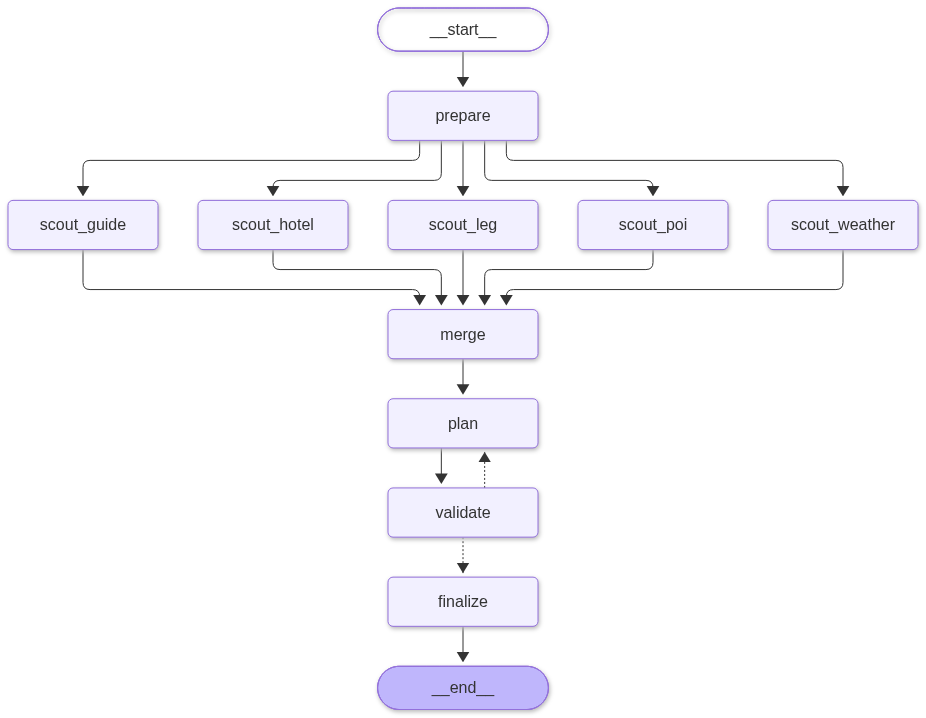

In [10]:
# ============================================================
# 组装 region_worker 子图
#   prepare ──┬─ scout_leg ────┐
#             ├─ scout_poi ────┤
#             ├─ scout_hotel ──┼─ merge → plan → validate ─┬─ finalize → END
#             ├─ scout_weather ┤                            └─ plan（回炉 1 次）
#             └─ scout_guide ──┘
# ============================================================
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

SCOUTS = [
    ("scout_leg", scout_leg),
    ("scout_poi", scout_poi),
    ("scout_hotel", scout_hotel),
    ("scout_weather", scout_weather),
    ("scout_guide", scout_guide),
]

w = StateGraph(WorkerState)
w.add_node("prepare", prepare)

for _name, _fn in SCOUTS:
    w.add_node(_name, _fn)
    w.add_edge("prepare", _name)            # 同一个源的多条边 = 同一 superstep 并行

w.add_node("merge", merge)
w.add_edge([n for n, _ in SCOUTS], "merge")  # 扇入：5 个都完成才跑

w.add_node("plan", plan_node)      # 节点名仍是 "plan"，函数名带 _node 防冲突
w.add_edge("merge", "plan")

w.add_node("validate", validate)
w.add_edge("plan", "validate")

w.add_node("finalize", finalize)
w.add_edge("finalize", END)
w.add_edge(START, "prepare")

w.add_conditional_edges(
    "validate",
    lambda s: "finalize" if (s.get("ok") or s.get("attempts", 0) >= 2) else "plan",
    {"plan": "plan", "finalize": "finalize"},
)

worker_graph = w.compile()
print("region_worker 子图编译完成")

try:
    display(Image(worker_graph.get_graph(xray=True).draw_mermaid_png()))
except Exception as e:
    print("（mermaid 渲染失败，已回退到文本版）", e)
    print(worker_graph.get_graph(xray=True).draw_mermaid())

## 第 9 部分 · 桥接层：父图节点 vs 子图

### 两种接法

**A. 把子图当节点直接加**（真正的 subgraph）

```python
builder.add_node("region_worker", worker_graph)
```

要求父子图的 state schema 能对上，否则要写转换。这里父图的 `region_plans` 和子图的 `local_plan` 名字、类型都不同，硬接会很别扭。

**B. 用一个普通节点包一层**（本 notebook 的选择）

```python
async def region_worker(payload: dict) -> dict:
    out = await worker_graph.ainvoke(payload)
    return {"region_plans": [out["local_plan"]]}
```

优点：**schema 边界清晰**，子图内部怎么改都不影响父图；还能在这一层做兜底（`LocalPlan.failed`）。
代价：父图拿不到子图内部的流式事件（想调试可以单独 `astream` 子图）。

> 选 B 的判断依据：**当父子状态结构差异大、且需要在边界做错误处理时，包装层比硬接更划算。**

### `Send` 的语义（很容易误解）

```python
Send("region_worker", {"region": r, "prev_city": ..., "next_city": ...})
```

- `Send` 用来做**数量在运行时才确定**的并行（这里是城市数量）
- 第二个参数是**这个节点的输入**，不是往 state 里合并的更新
- 所以节点函数收到的就是这个小 dict，**不是完整 state**
- 因为 `region` 不是 `PlanningState` 的字段，这里必须靠 `Send` 直传

### 为什么要传 `prev_city` / `next_city` / `home_city`

`region.origin` 对中间城市来说是"上一个城市"，但对**最后一座城**来说，它仍然是上一城——不是用户的家。

```
北京 → 太原 → 大同 → 平遥
                     ↑ origin 在这里是"大同"，但返程应该回"北京"
```

所以父图把这三个上下文显式传进来：

- `prev_city`：到达这段的出发地
- `next_city`：这段结束后去哪（`None` 表示这是最后一站）
- `home_city`：用户真正的出发地，用于最后一段的返程

> 这个坑很典型：**子图只知道自己那一段，跨段的语义必须由父图补。**

In [11]:
import traceback
from langgraph.types import Send


async def region_worker(payload: dict) -> dict:
    """父图节点：输入 {region, prev_city, next_city}，输出 {"region_plans": [LocalPlan]}"""
    region = payload["region"]
    plan = None
    try:
        out = await worker_graph.ainvoke(payload)
        plan = out.get("local_plan")
    except Exception as e:
        traceback.print_exc()
        plan = LocalPlan.failed(region, f"worker 异常：{e}")

    if plan is None:
        plan = LocalPlan.failed(region, "worker 未产出 local_plan")
    return {"region_plans": [plan]}


def fan_out_regions(state: PlanningState):
    """按城市段并行分发；顺带把前后城市传进去，解决「离开这天去哪」的边界问题"""
    rs = state["regions"]
    return [
        Send("region_worker", {
            "region": r,
            "prev_city": rs[i - 1].destination if i else state.get("origin"),
            "next_city": rs[i + 1].destination if i + 1 < len(rs) else None,
            "home_city": state.get("origin"),
        })
        for i, r in enumerate(rs)
    ]

## 第 10 部分 · synthesizer：为什么渲染也用代码

`plans = sorted(region_plans, key=start_date)` 之后，就是纯字符串拼接。

**为什么不让 LLM 写这份总攻略？**

1. 它已经有全部结构化数据了，再让模型"复述一遍"只会引入事实漂移
2. 排序、日期、金额都是确定性的
3. 输出格式要稳定（以后可能转 HTML / PDF / 日历），代码更容易改

渲染时用到 `status` 和 `warnings`：

```python
if any(p.status != "ok" for p in plans):
    lines.append("> ⚠️ 部分城市为降级输出")
...
if p.warnings:
    lines.append("⚠️ " + "；".join(p.warnings[:5]))
```

**降级要可见**，而不是把问题藏起来假装一切正常。

### 可以往下做的地方

- 换成 Jinja2 模板 / HTML，样式和内容分离
- 输出 `.ics` 日历（每个 item 一个事件）
- 按天拆分，接地图静态图

In [12]:
# ============================================================
# synthesizer：把 N 个 LocalPlan 渲染成一份攻略
# ============================================================
def _leg_line(leg: TransportLeg | None) -> str:
    if leg is None:
        return "—"
    bits = [leg.mode]
    if leg.service:
        bits.append(leg.service)
    if leg.from_station or leg.to_station:
        bits.append(f"{leg.from_station or '?'} → {leg.to_station or '?'}")
    if leg.depart or leg.arrive:
        bits.append(f"{leg.depart or '?'}–{leg.arrive or '?'}")
    if leg.duration_min:
        bits.append(f"约 {leg.duration_min} 分钟")
    if leg.price is not None:
        bits.append(f"约 ¥{leg.price:.0f}/人")
    text = " · ".join(bits)
    if leg.confidence != "high":
        text += "（方案级，待核实）"
    return text


def synthesizer(state: PlanningState) -> dict:
    plans = sorted(state.get("region_plans", []), key=lambda p: p.start_date)
    if not plans:
        return {"current_plan": "# 未生成任何城市计划\n"}

    lines = [f"# {state.get('origin')} → {state.get('destination')} 行程总览\n"]
    lines.append(
        f"> {state.get('travel_date')} ~ {state.get('travel_date_end')} · "
        f"{state.get('passengers', 1)} 人 · 总预算 {state.get('budget')}\n"
    )

    if any(p.status != "ok" for p in plans):
        lines.append("> ⚠️ 部分城市为降级输出，详见各段末尾的提示\n")

    for i, p in enumerate(plans):
        lines.append(f"\n---\n\n## {p.city}（{p.start_date} ~ {p.end_date} · {p.days} 天）\n")
        if p.inbound:
            lines.append(f"- **到达**：{_leg_line(p.inbound)}")
        if p.outbound:
            lines.append(f"- **离开**：{_leg_line(p.outbound)}")
        lines.append("")

        if not p.itinerary:
            lines.append("> ⚠️ 该城市规划失败\n")
            continue

        for d in p.itinerary:
            head = f"### Day {d.day} · {d.date}"
            if d.weekday:
                head += f" · {d.weekday}"
            if d.weather:
                head += f" · {d.weather.condition}"
            lines.append(head)
            for it in d.items:
                span = f"{it.start}" + (f"–{it.end}" if it.end else "")
                cost = f" 💰¥{it.cost:.0f}" if it.cost else ""
                lines.append(f"- **{span}** {it.title}{cost} — {it.note}")
            if d.backup:
                lines.append(f"- ☔ 备选：{d.backup}")
            lines.append("")

        if p.hotel.name:
            price = f" · 约 ¥{p.hotel.price_night:.0f}/晚" if p.hotel.price_night else ""
            lines.append(f"🏨 **{p.hotel.name}**（{p.hotel.area}）{price}")
            if p.hotel.why:
                lines.append(f"　 {p.hotel.why}")

        b = p.budget
        money = (f"\n💰 预算：交通 ¥{b.transport:.0f}｜住宿 ¥{b.hotel:.0f}｜"
                 f"门票 ¥{b.tickets:.0f}｜餐饮 ¥{b.food:.0f} = **¥{b.total:.0f}**")
        if p.budget_limit:
            money += f"（上限 ¥{p.budget_limit:.0f}）"
        lines.append(money)

        if p.guides:
            lines.append("\n📖 实用攻略：")
            for g in p.guides:
                tag = "" if g.confidence == "high" else "（待核实）"
                lines.append(f"- **{g.topic}**：{g.text}{tag}")

        if p.local_transport:
            lines.append("\n🚕 市内交通：")
            lines.extend(f"- {t}" for t in p.local_transport)

        if p.warnings:
            lines.append("\n⚠️ " + "；".join(p.warnings[:5]))

        if i < len(plans) - 1:
            nxt = plans[i + 1]
            lines.append(f"\n→ 下一站 **{nxt.city}**（{nxt.start_date}）")

    return {"current_plan": "\n".join(lines)}

## 第 11 部分 · 父图：整体拓扑

```python
travel_builder.add_edge(START, "orchestrator")
travel_builder.add_conditional_edges("orchestrator", fan_out_regions, ["region_worker"])
travel_builder.add_edge("region_worker", "synthesizer")
travel_builder.add_edge("synthesizer", END)
```

### 三个要点

**① `fan_out_regions` 返回的是 `Send` 列表，不是节点名。**

```python
return [Send("region_worker", {...}) for i, r in enumerate(rs)]
```

一个 `Send` = 一个并行任务。3 个城市就是 3 个 `region_worker` 同时跑。

**② `region_worker` 出现在 `path_map` 里，但实际执行的是 N 个实例。**

`["region_worker"]` 只是告诉画图工具"可能去这里"。真正决定跑几次的是 `Send` 列表的长度。

**③ `synthesizer` 前的这条边是隐式 barrier。**

N 个 worker 都写到 `region_plans`（`operator.add`），`synthesizer` 会等**全部** worker 完成后才执行一次。
所以 `synthesizer` 里拿到的一定是完整的 N 份计划——不需要自己写"等所有分支结束"的逻辑。

### 完整时序

```
START
 └─ orchestrator            （1 次 LLM 调用，拆出 N 个 RegionDraft）
     └─ Send × N
         ├─ region_worker#1  ┐
         ├─ region_worker#2  ├─ 并行，各自跑完内部子图
         └─ region_worker#N  ┘
             └─ region_plans（operator.add 合并）
                 └─ synthesizer
                     └─ END
```

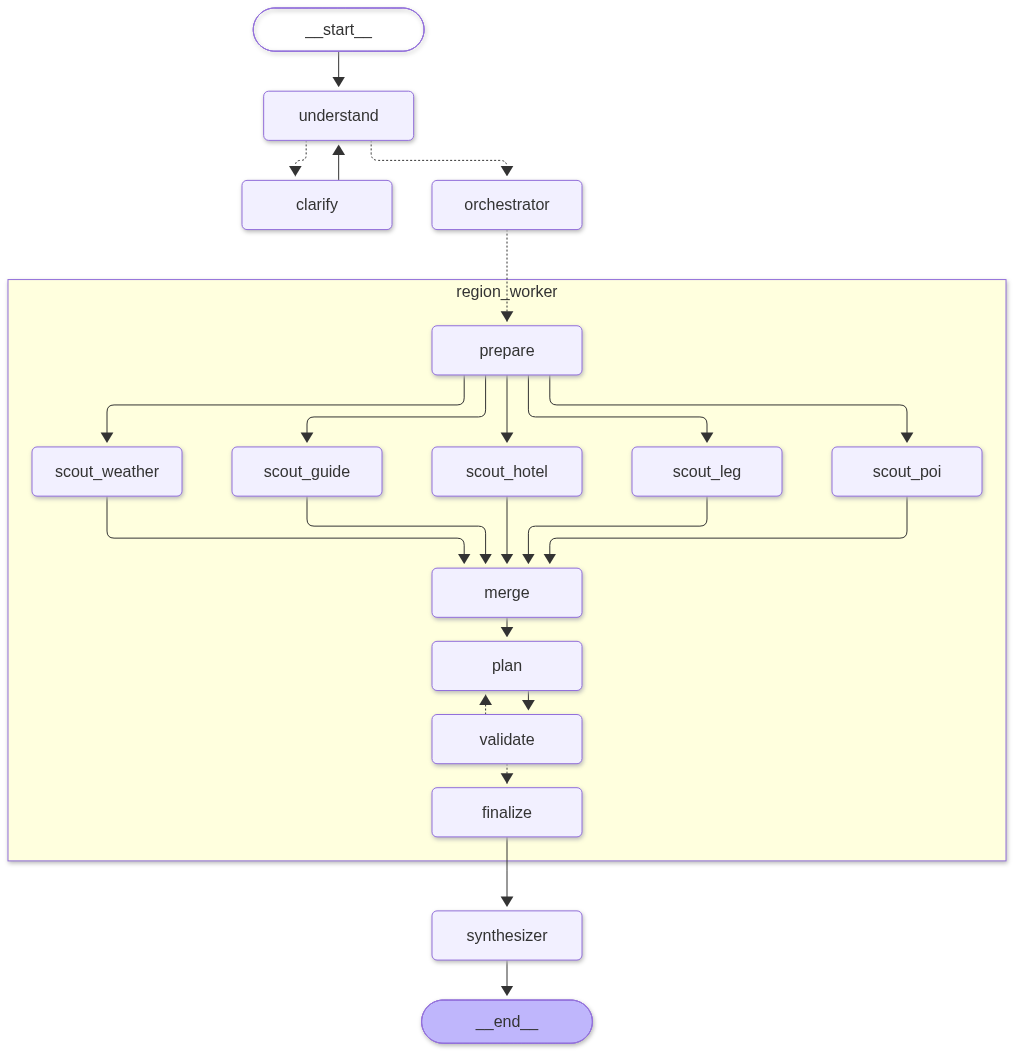

In [13]:
from langgraph.graph import StateGraph
from langgraph.constants import START, END
from IPython.display import Image, display

travel_builder = StateGraph(PlanningState)
travel_builder.add_node("understand",   understand)
travel_builder.add_node("clarify",      clarify)
travel_builder.add_node("orchestrator", orchestrator)
travel_builder.add_node("region_worker", region_worker)
travel_builder.add_node("synthesizer",   synthesizer)

# 入口：先理解需求；缺信息就中断追问，补完再重新抽取
travel_builder.add_edge(START, "understand")
travel_builder.add_conditional_edges(
    "understand",
    route_entry,
    {"clarify": "clarify", "orchestrator": "orchestrator"},
)
travel_builder.add_edge("clarify", "understand")

travel_builder.add_conditional_edges("orchestrator", fan_out_regions, ["region_worker"])
travel_builder.add_edge("region_worker", "synthesizer")
travel_builder.add_edge("synthesizer", END)

# interrupt 必须配 checkpointer；thread_id 就是会话 id
# 图是异步跑的，所以要用 AsyncSqliteSaver（同步版不支持 ainvoke）
import aiosqlite
from langgraph.checkpoint.sqlite.aio import AsyncSqliteSaver

DB_PATH = ROOT / "db" / "travel.db"
DB_PATH.parent.mkdir(parents=True, exist_ok=True)

# 重跑这个 cell 时复用已有连接，否则会开一堆 sqlite 连接导致 database is locked
try:
    checkpointer
except NameError:
    _conn = await aiosqlite.connect(str(DB_PATH))
    checkpointer = AsyncSqliteSaver(_conn)
    await checkpointer.setup()

travel_graph = travel_builder.compile(checkpointer=checkpointer)

try:
    display(Image(travel_graph.get_graph(xray=True).draw_mermaid_png()))
except Exception as e:
    print("（mermaid 渲染失败，已回退到文本版）", e)
    print(travel_graph.get_graph(xray=True).draw_mermaid())

## 第 12 部分 · 怎么跑、怎么调

### 两种运行方式

**单城市（推荐先跑这个）**

```python
out = await region_worker({"region": region, "prev_city": "北京",
                           "next_city": None, "home_city": "北京"})
```

跳过 `orchestrator`，直接喂一个 `RegionDraft`。出问题时范围小，好定位。

**全图**

```python
async for chunk in travel_graph.astream(initial_state, stream_mode="values"):
```

`stream_mode="values"` 表示每一步把**完整 state** 推给你（还有 `updates` 只看增量、`messages` 只看 token 流）。

### 调试清单

| 现象 | 先看哪里 |
|---|---|
| 输出全是"未匹配景点" | `plan` 是不是降级了 → 看 `plan.warnings` 有没有 `[plan] LLM 调用失败` |
| `[validate] 引用了不存在的候选` | 模型编了 id → 检查 `index` 是否太小、prompt 是否说清了 id |
| `时间重叠` | 模型没按 `duration_min` 排 → 可以在 prompt 里加"必须 start + duration 才排下一个" |
| `预算超支` | 正常，说明约束生效 → 调 `budget` 或加酒店档位降级 |
| 画图报错 | `draw_mermaid_png` 需要联网 → 已自动回退到文本版 mermaid |
| `region_plans` 越来越多 | `operator.add` 累积 → 重跑前重建 `initial_state` |

### 改 prompt 的正确姿势

改 `PLAN_SYSTEM` 时，**同步问自己：这条规则 validate 能查吗？**
能查就加进 validate（硬约束）；不能查（比如"安排得合理一点"）就只放在 prompt 里，并接受它不被保证。

In [14]:
# ============================================================
# 单城市冒烟测试：不走 orchestrator，直接喂一个 RegionDraft
# ============================================================
region = RegionDraft(
    origin="北京", destination="太原",
    start_date="2026-11-20", end_date="2026-11-22",
    budget="2000元", passengers=2, interests="历史",
    transport_mode="公共交通",
)

out = await region_worker({"region": region, "prev_city": "北京",
                           "next_city": None, "home_city": "北京"})
plan = out["region_plans"][0]

print(f"status = {plan.status}")
print(f"city = {plan.city}, days = {plan.days}, 行程天数 = {len(plan.itinerary)}")
print("inbound :", _leg_line(plan.inbound))
print("outbound:", _leg_line(plan.outbound))
for d in plan.itinerary:
    print(f"\nDay {d.day} {d.date} {d.weekday} "
          f"{d.weather.condition if d.weather else ''}")
    for it in d.items:
        cost = f" ¥{it.cost:.0f}" if it.cost else ""
        print(f"  {it.start}-{it.end} [{it.kind}] {it.title}{cost}")

print(f"\nbudget = {plan.budget.model_dump()}  total = {plan.budget.total}")
print("warnings =", plan.warnings)

status = partial
city = 太原, days = 3, 行程天数 = 3
inbound : 高铁 · G644（模拟） · 北京站 → 太原站 · 08:00–12:30 · 约 270 分钟 · 约 ¥150/人（方案级，待核实）
outbound: 高铁 · G644（模拟） · 太原站 → 北京站 · 15:00–19:30 · 约 270 分钟 · 约 ¥150/人（方案级，待核实）

Day 1 2026-11-20 周五 晴
  12:30-13:30 [rest] 抵达太原，酒店放行李
  13:40-14:40 [meal] 柳巷面食午餐
  14:50-17:20 [sight] 山西督军府旧址(晋商博物院)
  17:30-18:30 [meal] 钟楼街晚餐
  19:00-20:00 [sight] 迎泽公园
  20:30-21:30 [meal] 柳巷小吃宵夜

Day 2 2026-11-21 周六 多云
  09:00-11:30 [sight] 山西博物院
  12:00-13:00 [meal] 长风商务区午餐
  13:30-16:00 [sight] 太原北齐壁画博物馆
  16:30-17:30 [meal] 市区简餐
  17:40-18:40 [sight] 双塔公园
  19:00-20:00 [meal] 双塔周边晚餐

Day 3 2026-11-22 周日 小雨
  09:00-10:00 [meal] 酒店早餐后退房
  10:10-12:40 [sight] 晋祠博物馆 ¥80

budget = {'transport': 600.0, 'hotel': 640.0, 'tickets': 160.0, 'food': 480.0, 'other': 0}  total = 1880.0
warnings = ['已自动调整 6 处时间冲突/超时安排']


In [15]:
# ============================================================
# 第 1 步：用一句自然语言发起规划
# 缺信息时图会停在 interrupt，这里把问题打印出来
# ============================================================
import uuid
from langchain_core.messages import HumanMessage
from IPython.display import Markdown

CONFIG = {"configurable": {"thread_id": f"demo-{uuid.uuid4().hex[:6]}"}}
USER_TEXT = "帮我安排北京到山西的旅游规划"

result = await travel_graph.ainvoke(
    {
        "messages": [HumanMessage(content=USER_TEXT)],
        "user_input": USER_TEXT,
        "clarify_rounds": 0,
    },
    CONFIG,
)

if result.get("__interrupt__"):
    payload = result["__interrupt__"][0].value
    print("⚠️ 信息不全：", payload["ask"])
    print("已识别：", payload["known"])
else:
    print("信息齐全，已直接生成。")
    display(Markdown(result.get("current_plan", "")))

⚠️ 信息不全： 还需要你补充：出发日期、返程日期
已识别： {'origin': '北京', 'destination': '山西'}


In [16]:
# ============================================================
# 第 2 步：补充信息，继续同一个会话（thread_id 不变）
# ============================================================
from langgraph.types import Command

REPLY = "10月1日出发，10月7日回来，2个人，预算5000元，喜欢历史"

result = await travel_graph.ainvoke(Command(resume=REPLY), CONFIG)

if result.get("__interrupt__"):
    print("还在追问：", result["__interrupt__"][0].value["ask"])
else:
    display(Markdown(result.get("current_plan", "")))

# 北京 → 山西 行程总览

> 2026-10-01 ~ 2026-10-07 · 2 人 · 总预算 5000元

> ⚠️ 部分城市为降级输出，详见各段末尾的提示


---

## 大同（2026-10-01 ~ 2026-10-03 · 3 天）

- **到达**：高铁 · G750（模拟） · 北京站 → 大同站 · 08:00–10:30 · 约 150 分钟 · 约 ¥150/人（方案级，待核实）

### Day 1 · 2026-10-01 · 周四 · 晴
- **11:00–12:00** 古城内面馆午餐 — 
- **12:30–14:00** 华严寺 💰¥50 — 华严寺90分钟，17:30关门，室内古建
- **14:20–15:05** 九龙壁 💰¥10 — 九龙壁45分钟
- **15:30–18:00** 大同古城 — 大同古城漫步120分钟（缩短以留晚餐）
- **18:10–19:10** 古城鼓楼附近晚餐 — 
- **19:30–20:30** 古城夜景散步回客栈 — 

### Day 2 · 2026-10-02 · 周五 · 多云
- **08:30–11:00** 云冈石窟 💰¥120 — 云冈石窟150分钟，需预约，建议先预约8:30场
- **11:20–12:20** 景区附近简餐 — 
- **12:40–13:40** 返回市区（约40分钟） — 
- **13:50–16:20** 大同市博物馆 — 大同市博物馆150分钟，需预约，室内
- **16:30–17:30** 御东新区晚餐 — 
- **18:00–19:00** 回古城客栈休息 — 

### Day 3 · 2026-10-03 · 周六 · 小雨
- **09:00–10:30** 善化古寺 💰¥40 — 善化古寺90分钟，室内古建，小雨天适宜
- **10:45–11:45** 古城早茶/午餐 — 
- **12:00–14:00** 东南邑历史文化街区 — 东南邑历史文化街区120分钟
- **14:30–15:30** 街区咖啡甜点 — 
- **16:00–17:00** 取行李前往大同南站（14:30后留足90分钟余量） — 

🏨 **古城内·示例客栈**（大同古城） · 约 ¥280/晚
　 景点全在步行范围

💰 预算：交通 ¥300｜住宿 ¥560｜门票 ¥440｜餐饮 ¥480 = **¥1780**（上限 ¥2000）

📖 实用攻略：
- **交通**：古城内景点集中，步行即可，不用打车（待核实）
- **预约**：云冈石窟旺季限流，建议提前 1 天购票（待核实）
- **美食**：刀削面、羊杂、烧麦（待核实）
- **避坑**：悬空寺在浑源县，距市区约 1.5 小时，需单独安排半天（待核实）

⚠️ 已自动调整 2 处时间冲突/超时安排

→ 下一站 **太原**（2026-10-04）

---

## 太原（2026-10-04 ~ 2026-10-05 · 2 天）

- **到达**：高铁 · G772（模拟） · 大同站 → 太原站 · 08:00–11:30 · 约 210 分钟 · 约 ¥150/人（方案级，待核实）

### Day 1 · 2026-10-04 · 周日 · 晴
- **11:30–12:30** 到站休整、放行李 — 
- **12:40–13:40** 长风商务区午餐（面食） — 
- **13:50–16:20** 晋祠景区 💰¥80 — 晋祠景区，建议150分钟，80元×2
- **16:30–17:30** 返回市区 — 
- **17:40–18:40** 双塔公园 — 双塔公园，60分钟，免费
- **18:50–19:50** 柳巷晚餐 — 
- **20:10–21:10** 回酒店休息 — 

### Day 2 · 2026-10-05 · 周一 · 多云
- **12:00–13:00** 博物院附近午餐 — 
- **16:20–17:20** 回酒店取行李 — 
- **17:30–18:30** 太原南站附近简餐 — 
- **18:40–19:40** 赴太原南站乘车去平遥 — 

🏨 **长风商务区·示例酒店**（长风商务区） · 约 ¥260/晚
　 离山西博物院近，环境安静

💰 预算：交通 ¥300｜住宿 ¥260｜门票 ¥160｜餐饮 ¥320 = **¥1040**（上限 ¥1400）

📖 实用攻略：
- **交通**：地铁 2 号线连接火车站与市区，公交 / 地铁均可扫码乘车（待核实）
- **预约**：山西博物院免费，但需提前 1-3 天在公众号预约（待核实）
- **美食**：认一力羊肉蒸饺、头脑（冬季早餐）、刀削面（待核实）
- **避坑**：晋祠离市区约 25 公里，不要和市区景点排在同半天（待核实）

⚠️ 已自动调整 6 处时间冲突/超时安排

→ 下一站 **平遥**（2026-10-06）

---

## 平遥（2026-10-06 ~ 2026-10-07 · 2 天）

- **到达**：高铁 · G777（模拟） · 太原站 → 平遥站 · 08:00–11:30 · 约 210 分钟 · 约 ¥150/人（方案级，待核实）
- **离开**：高铁 · G755（模拟） · 平遥站 → 北京站 · 15:00–17:30 · 约 150 分钟 · 约 ¥150/人（方案级，待核实）

### Day 1 · 2026-10-06 · 周二 · 晴
- **12:00–13:00** 古城内客栈午餐（莜面栲栳栳） — 
- **13:10–15:40** 平遥县衙博物馆 — 午餐后步行至县衙，建议150分钟
- **15:50–17:30** 协同庆(中国钱庄博物馆) — 钱庄博物馆，室内为主，建议150分钟
- **18:00–19:00** 南大街老街晚餐 — 
- **19:10–19:55** 市楼 — 市楼夜景，45分钟
- **20:05–21:05** 回客栈休息 — 

### Day 2 · 2026-10-07 · 周三 · 多云
- **08:00–09:00** 平遥文庙 — 文庙参观，60分钟
- **09:15–10:15** 城隍庙 — 城隍庙参观，60分钟
- **10:30–11:30** 古城早餐/早午餐（碗托、平遥牛肉） — 
- **11:40–13:10** 平遥古城墙 💰¥130 — 古城墙参观，90分钟；部分段修缮，费用含在古城通票内

🏨 **古城内·示例客栈**（平遥古城） · 约 ¥260/晚
　 住在古城里，早晚人少好拍照

💰 预算：交通 ¥600｜住宿 ¥260｜门票 ¥260｜餐饮 ¥320 = **¥1440**（上限 ¥1600）

📖 实用攻略：
- **交通**：古城内禁行机动车，行李建议用客栈的摆渡车（待核实）
- **门票**：古城通票 3 日有效，含 20 多个景点，比单买划算（待核实）
- **美食**：平遥牛肉、栲栳栳、碗托（待核实）
- **避坑**：双林寺、镇国寺在城外，需打车前往（待核实）

⚠️ 已自动调整 7 处时间冲突/超时安排

---

# 附录

## A. 术语表

| 术语 | 含义 |
|---|---|
| **superstep** | LangGraph 的一轮执行：一批可并行的节点同时跑，结束时统一合并写入 |
| **channel / reducer** | State 的每个 key 是一个 channel；reducer 决定并发写入怎么合并 |
| **扇出 / 扇入** | 一个节点连多条边出去 = 并行；多条边汇到同一节点 = 等齐再跑 |
| **`Send`** | 运行时动态生成并行任务，第二个参数是该节点的输入 |
| **子图** | 一个编译好的 `StateGraph` 当作另一个图的节点（本 notebook 用的是"包装一层"的变体） |
| **结构化输出** | `llm.with_structured_output(Schema)`，直接拿到 Pydantic 对象 |
| **agent-as-tool** | 把一个 agent 包成工具给另一个 agent 调用（本项目在取数场景下放弃了它） |

## B. 这份代码的三个"为什么"

1. **为什么要 `index`？**
   给 LLM 一个封闭的候选集，让"编造景点"在结构上不可能，而不是靠 prompt 恳求。

2. **为什么 scout 是节点不是 agent？**
   取数是参数固定的确定性操作，用 agent 只会带来随机顺序、串行、多轮 token。

3. **为什么 finalize 要重算时间？**
   LLM 只负责"选哪些、先后顺序"，具体几点到几点由代码按 `duration_min` 推进——**算数不要交给模型**。

## C. 接高德 MCP 的清单

- [ ] 打印全部工具名：`print([t.name for t in await adapter.list_tools()])`
- [ ] `scout_poi` → `maps_text_search` / `maps_around_search` + `maps_search_detail`（拿开放时间、门票）
- [ ] `scout_hotel` → `maps_around_search`（类型=住宿）
- [ ] `scout_weather` → `maps_weather`，超出预报窗口回落 `source="climate"`
- [ ] `scout_leg` → `maps_geo` + `maps_direction_transit_integrated`（或 `driving`）
- [ ] 把 `source="mock"` 改成 `"amap"`
- [ ] MCP 客户端生命周期跟 app 走，不要 `async with` 完就丢

## D. 下一步增强（按性价比排序）

1. **片区聚类**：用 POI 坐标把每天的景点限制在同一片区域，减少折返（现在完全靠 LLM）
2. **真实班次/票价**：接 12306 或搜索，补上 `service` / `price`
3. **雨天自动换室内**：`weather.condition` 有小雨时，把 outdoor 类 POI 换成室内候选
4. **预算优化**：超预算时自动降酒店档位，而不是只报警告
5. **多轮修改**：加 checkpointer + `interrupt`，让用户说"第 3 天太赶了"
6. **缓存**：`scout_poi` 按 (城市, 兴趣) 缓存，同城多次规划不重复查

## E. 一句话总结

> **父图负责"分工"，子图负责"查证 + 编排"，LLM 只在"选和排"这一处出现，其余全是可测的代码。**